<div style="border:solid Chocolate 2px; padding: 40px">

<b>Привет!</b>

Меня зовут Евгений Головин, я буду ревьюером твоего проекта. Если ты не против, то предлагаю построить наше общение на "ты" ;) Если удобнее на "вы", то нет проблем, только скажи об этом.

В ходе работы я оставил тебе комментарии <font color='green'>зеленого</font>, <font color='gold'>желтого</font> и <font color='red'>красного</font> цветов. Сейчас объясню, что они значат:

<br/>

<div class="alert alert-success">
<h2> Комментарий ревьюера <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Решение на этом шаге является полностью правильным.
</div>

<br/>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера <a class="tocSkip"> </h2>

<b>Небольшие замечания и рекомендации💡:</b> Решение на этом шаге станет еще лучше, если внести небольшие коррективы.
</div>


<br/>
<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера <a class="tocSkip"></h2>


<b>На доработку🤔:</b>
 Решение на этом шаге требует существенной переработки и внесения правок. Напоминаю, что проект не может быть принят с первого раза, если ревью содержит комментарии, рекомендующие доработать шаги.
</div>

Увидев мой комментарий, не удаляй его, он будет очень полезен в случае повторной проверки работы :)

<div class="alert alert-info">
<b>А свой помечай вот так, чтобы я его не потерял ;)</b>
</div>

На мои комменатрии можно и нужно реагировать, только делать это стоит так, чтобы твои и мои комменты не смешались: выделяй свои цветами, сильно отличающимися от моих.

Увидев у тебя неточность, в первый раз я лишь укажу на ее наличие и дам тебе возможность самому найти и исправить ее. На реальной работе твой руководитель будет поступать также, и я пытаюсь подготовить тебя именно к работе аналитиком. Но если ты пока не справишься с такой задачей - при следующей проверке я дам более точную подсказку!
</div>

<div class="alert alert-info">
<b> Евгений, привет! Спасибо большое за ценные рекомендации и комменты! Для меня это очень важно </b>
</div>

# Проект: семантический поиск товаров по текстовому запросу

**Ваша роль.** Вы специалист по Data Science. Компания развивает онлайн-каталог товаров, и сейчас руководству кажется, что классический поиск по ключевым словам плохо справляется с реальными запросами. Пользователи пишут названия с ошибками, кириллицей, используют просторечные слова, ищут товары по назначению, а не по функциональности («удобные кроссовки для бега» вместо «мужские спортивные кроссовки с амортизацией»). Команда хочет проверить, поможет ли векторный поиск улучшить качество поисковой системы.

**Задача.** Вам нужно построить MVP системы семантического поиска, сравнить его с лексической baseline-моделью на подготовленной разметке и дать бизнесу обоснованную рекомендацию о том, где новое решение помогает, где ошибается и стоит ли его вообще внедрять.

## Данные

| Файл | Что это | Когда нужен |
|---|---|---|
| wb_products_raw_sample.parquet | Исходный каталог, ~200 тысяч строк, все категории. <br> Вам нужно самостоятельно отобрать рабочее подмножество этих данных | Недели 1–2 |
| wb_products_dedup.parquet | Пул асессоров: множество товаров, по которому делалась разметка | Неделя 2, раздел 4 |
| queries_synthetic_train.parquet | Разметка релевантности, train | Недели 2–3 |
| queries_synthetic_test.parquet | Разметка релевантности, test | **один прогон** в конце недели 3 |

Файлы с разметкой содержат четыре столбца: `query_id`, `query_text`, `item_id`, `relevance`. Шкала в `relevance` от `0` до `3`, где `0` — товар нерелевантен, а `3` — максимально релевантен. Связь с каталогом: `item_id` ↔ `imt_id`.

In [1]:
# Необходимые файлы

RAW_PRODUCTS_PATH = "wb_products_raw_sample.parquet"
ASSESSED_POOL_PATH = "wb_products_dedup.parquet"
TRAIN_QUERIES_PATH = "queries_synthetic_train.parquet"
TEST_QUERIES_PATH = "queries_synthetic_test.parquet"

In [2]:
# Устанавливаем pip
%pip install scikit-learn sentence-transformers mlflow -q

Note: you may need to restart the kernel to use updated packages.


In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer
import mlflow

# Стандартные библиотеки
import os
import re
import json
from collections import defaultdict

# Работа с данными
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Доступ к S3
import s3fs
from dotenv import load_dotenv

load_dotenv()

# Визуализация
import matplotlib.pyplot as plt
import seaborn as sns






/Users/artemsaenko/opt/anaconda3/envs/semsearch/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# Единый SEED для всех случайных операций в проекте 
SEED = 42
np.random.seed(SEED)


In [5]:
ENDPOINT_URL = "https://storage.yandexcloud.net"
SOURCE_BUCKET = "s3-ds-source"  # общий бакет с исходными данными проекта

fs = s3fs.S3FileSystem(
    key=os.environ["S3_ACCESS_KEY"],
    secret=os.environ["S3_SECRET_KEY"],
    client_kwargs={"endpoint_url": ENDPOINT_URL},
)

FILES_TO_DOWNLOAD = [
    RAW_PRODUCTS_PATH,
    ASSESSED_POOL_PATH,
    TRAIN_QUERIES_PATH,
    TEST_QUERIES_PATH,
]

for filename in FILES_TO_DOWNLOAD:
    if not os.path.exists(filename):
        fs.get(f"{SOURCE_BUCKET}/{filename}", filename)
        print(f"Скачан: {filename}")
    else:
        print(f"Уже есть локально: {filename}")

Уже есть локально: wb_products_raw_sample.parquet
Уже есть локально: wb_products_dedup.parquet
Уже есть локально: queries_synthetic_train.parquet
Уже есть локально: queries_synthetic_test.parquet


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Хороший старт: пути к файлам вынесены в константы, `SEED` зафиксирован один раз для всего проекта, а ключи доступа к S3 берутся из `.env` и не светятся в тетрадке — это правильная гигиена секретов. Проверка `os.path.exists` перед скачиванием тоже приятная мелочь: при перезапуске файлы не грузятся заново.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Немного наведи порядок в «шапке» тетрадки: `re` импортируется дважды, `pd.set_option(...)` и `load_dotenv()` тоже вызываются по два раза, а `math`, `NearestNeighbors` и `cosine_similarity` дальше нигде не используются. На результат это не влияет, но чистые импорты — первое, что видит коллега, открывший твой ноутбук.
</div>

<div class="alert alert-info">
<b> Исправил </b>
</div>

---

## Неделя 1 — знакомство с данными и EDA

**Цель** — понять, с какими данными работаете, чтобы принять обоснованные решения:

- выбрать категории, с которыми будете работать;
- определить, как будете очищать описания от всего лишнего;
- решить, из каких полей собирать текст товара.

**Главный критерий успеха:** любое ваше решение по данным вы можете подкрепить ссылкой на конкретные результаты анализа.

### 1. Загрузка данных

Загрузите каталог и обе разметки. Изучите их структуру: проанализируйте колонки и типы данных в них, определите, что описывает одна строка.

**Подсказка.** `imt_id` — карточка товара, `nm_id` — конкретный артикул этого товара, то есть его разновидность, отличающаяся цветом, размером или чем-то ещё. Определите, что из этого должен возвращать поиск, — от этого зависит, на каком уровне вы будете строить индекс.

In [6]:
df_raw = pd.read_parquet(RAW_PRODUCTS_PATH)
queries_train = pd.read_parquet(TRAIN_QUERIES_PATH, engine="fastparquet")
queries_test = pd.read_parquet(TEST_QUERIES_PATH, engine="fastparquet")

for name, df in [("wb_products_raw_sample", df_raw),
                  ("queries_synthetic_train", queries_train),
                  ("queries_synthetic_test", queries_test)]:
    print(f"=== {name} ===")
    print("Размер:", df.shape)
    print("Типы:\n", df.dtypes)
    print("Первые строки:")
    display(df.head())
    print()

=== wb_products_raw_sample ===
Размер: (200000, 9)
Типы:
 imt_id              int64
nm_id               int64
imt_name           object
subj_name          object
subj_root_name     object
nm_colors_names    object
vendor_code        object
description        object
brand_name         object
dtype: object
Первые строки:


,imt_id,nm_id,imt_name,subj_name,subj_root_name,nm_colors_names,vendor_code,description,brand_name
0,100000,118982,Сумка,Сумки,Аксессуары,бежевый,82992/beige,,Pola
1,1000000,1206857,Шапка,Шапки,Головные уборы,белый,Лаки/белый,,Ваша Шляпка
2,1000000,1206860,Шапка,Шапки,Головные уборы,черный,Лаки/черный,,Ваша Шляпка
3,10000000,13349975,Очки TRUESPIN Fold,Солнцезащитные очки,Аксессуары,черный,20S.Y.T.35.00.564/Black/Black,,True Spin
4,10000001,13349981,Очки TRUESPIN Candor,Солнцезащитные очки,Аксессуары,черный,20S.Y.T.35.00.567/Black,,True Spin



=== queries_synthetic_train ===
Размер: (11453, 4)
Типы:
 query_id      object
query_text    object
item_id        int64
relevance      int64
dtype: object
Первые строки:


,query_id,query_text,item_id,relevance
0,SYN_000001,жилеты на пуговицах,100211,3
1,SYN_000001,жилеты на пуговицах,100433,1
2,SYN_000001,жилеты на пуговицах,1000988,1
3,SYN_000001,жилеты на пуговицах,1016032,1
4,SYN_000001,жилеты на пуговицах,10001023,1



=== queries_synthetic_test ===
Размер: (4866, 4)
Типы:
 query_id      object
query_text    object
item_id        int64
relevance      int64
dtype: object
Первые строки:


,query_id,query_text,item_id,relevance
0,SYN_000003,кардиганы на пуговицах,1000028,1
1,SYN_000003,кардиганы на пуговицах,1000628,3
2,SYN_000003,кардиганы на пуговицах,1008849,2
3,SYN_000003,кардиганы на пуговицах,10002779,1
4,SYN_000003,кардиганы на пуговицах,10007028,2


**Проверьте связность данных:** все ли `item_id` из разметки есть в каталоге, нет ли пересечения `query_id` между `train` и `test`.

In [7]:
catalog_imt_ids = set(df_raw["imt_id"])

train_item_ids = set(queries_train["item_id"])
test_item_ids = set(queries_test["item_id"])

print("Всего строк в каталоге:", len(df_raw))
print("Уникальных imt_id в каталоге:", df_raw["imt_id"].nunique())
print("Уникальных nm_id в каталоге:", df_raw["nm_id"].nunique())
print("Полных дублей по imt_id:", df_raw["imt_id"].duplicated().sum())

print("\nitem_id из train, отсутствующие в каталоге:",
      len(train_item_ids - catalog_imt_ids))
print("item_id из test, отсутствующие в каталоге:",
      len(test_item_ids - catalog_imt_ids))

train_query_ids = set(queries_train["query_id"])
test_query_ids = set(queries_test["query_id"])
overlap_queries = train_query_ids & test_query_ids

print("\nПересечение query_id между train и test:", len(overlap_queries))
print("Пересечение по тексту запроса между train и test:",
      len(set(queries_train["query_text"]) & set(queries_test["query_text"])))

Всего строк в каталоге: 200000
Уникальных imt_id в каталоге: 174427
Уникальных nm_id в каталоге: 199957
Полных дублей по imt_id: 25573

item_id из train, отсутствующие в каталоге: 0
item_id из test, отсутствующие в каталоге: 0

Пересечение query_id между train и test: 0
Пересечение по тексту запроса между train и test: 0


**Что описывает одна строка.** 

В `wb_products_raw_sample.parquet` 200 000 строк, но только 174 427 уникальных `imt_id` — то есть одному `imt_id` (карточке-модели) соответствует несколько строк. При этом уникальных `nm_id` — 199 957, почти равно числу строк: одна строка каталога описывает один артикул (`nm_id`), то есть конкретный цвет/размер товара, а не карточку целиком. Это подтверждает решение, принятое на встрече с наставником: индексировать нужно на уровне `imt_id` («штрихкод», объединяющий все варианты), а для этого сначала предстоит дедуплицировать сырую выгрузку до одной строки на `imt_id` (шаг 2, неделя 2).

**Полных дублей по `imt_id`:** 25 573 «лишних» строк (200 000 − 174 427) — то есть в среднем на карточку приходится больше одного артикула. Это ожидаемо: у одного товара может быть несколько цветов/размеров.

**Разметка.** `queries_synthetic_train.parquet` — 11 453 строки, `queries_synthetic_test.parquet` — 4 866 строк, у обоих одинаковая структура: `query_id`, `query_text`, `item_id`, `relevance`.

**Связность с каталогом.** Все `item_id` из train и test присутствуют в каталоге (`imt_id`) — несовпадений нет, расхождений устранять не потребуется.

**Разбивка train/test.** Пересечений `query_id` между train и test — 0, пересечений по тексту запроса — тоже 0. Утечки между выборками нет, разбивка сделана корректно ещё на этапе подготовки данных заказчиком.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Структура данных разобрана точно: посчитаны `imt_id` и `nm_id`, сделан правильный вывод, что строка — это артикул, а индекс нужно строить на уровне карточки. Проверки связности сделаны полностью: все товары разметки есть в каталоге, `query_id` между train и test не пересекаются.

Отдельно отмечу проверку пересечения **текстов** запросов — многие ограничиваются только ID, а утечка часто прячется именно в одинаковых формулировках под разными идентификаторами.
</div>

### 2. EDA

In [8]:
print("Уникальные корневые категории (subj_root_name):")
print(df_raw["subj_root_name"].value_counts())

Уникальные корневые категории (subj_root_name):
subj_root_name
Одежда                    43316
Аксессуары                16446
Дом                       15024
Обувь                     13187
Красота                    9895
                          ...  
Игровые консоли и игры       67
Электротранспорт             47
Торговое оборудование        21
Сетевое оборудование         21
                              8
Name: count, Length: 65, dtype: int64


In [9]:
# Проверка: в каких категориях лежат размеченные товары
labeled_item_ids = train_item_ids | test_item_ids
labeled_categories = df_raw.loc[
    df_raw["imt_id"].isin(labeled_item_ids), "subj_root_name"
].unique()
print("Корневые категории, в которых лежат размеченные item_id:", labeled_categories)

# Фильтрация до целевых категорий (по результатам предыдущей ячейки)
TARGET_ROOT_CATEGORIES = ["Одежда", "Обувь"]

assert set(labeled_categories) <= set(TARGET_ROOT_CATEGORIES), (
    "Среди размеченных товаров есть категории вне выбранных — фильтрация потеряет часть разметки"
)

df_scope = df_raw[df_raw["subj_root_name"].isin(TARGET_ROOT_CATEGORIES)].copy()

print(f"Строк после фильтрации до {TARGET_ROOT_CATEGORIES}: {len(df_scope)}")
print(f"Уникальных imt_id: {df_scope['imt_id'].nunique()}")
print(f"Уникальных subj_name: {df_scope['subj_name'].nunique()}")

# Проверка: после фильтрации ни один размеченный item_id не потерян
lost_labeled_ids = labeled_item_ids - set(df_scope["imt_id"])
assert len(lost_labeled_ids) == 0, f"Потеряно {len(lost_labeled_ids)} размеченных item_id после фильтрации категорий"
print("Все размеченные item_id сохранены после фильтрации категорий.")



Корневые категории, в которых лежат размеченные item_id: ['Одежда' 'Обувь']
Строк после фильтрации до ['Одежда', 'Обувь']: 56503
Уникальных imt_id: 48489
Уникальных subj_name: 104
Все размеченные item_id сохранены после фильтрации категорий.


<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Выбор «Одежды» и «Обуви» верный, но в выводах он обоснован фразой «только по ним есть оценки релевантности», а в коде это нигде не проверено. Любое решение по данным лучше подкреплять конкретной ячейкой: посмотри, в каких `subj_root_name` лежат товары из train и test, и убедись, что после фильтрации ни один размеченный `item_id` не потерялся. Одна строчка с `assert` здесь сильно добавит уверенности в пайплайне.
</div>

<div class="alert alert-info">
<b> Исправил </b>
</div>

In [10]:
# --- Полнота полей: NaN и пустые строки ---
text_cols = ["imt_name", "description", "nm_colors_names", "subj_name", "brand_name"]

missing_report = pd.DataFrame({
    "nan_count": df_scope[text_cols].isna().sum(),
    "nan_pct": (df_scope[text_cols].isna().mean() * 100).round(2),
    "empty_string_count": (df_scope[text_cols] == "").sum(),
})
missing_report["empty_string_pct"] = (missing_report["empty_string_count"] / len(df_scope) * 100).round(2)
missing_report["total_missing_pct"] = (missing_report["nan_pct"] + missing_report["empty_string_pct"]).round(2)

print("\n=== Пропуски (NaN + пустая строка) ===")
display(missing_report)




=== Пропуски (NaN + пустая строка) ===


,nan_count,nan_pct,empty_string_count,empty_string_pct,total_missing_pct
imt_name,0,0.0,273,0.48,0.48
description,0,0.0,34070,60.30,60.30
nm_colors_names,0,0.0,1013,1.79,1.79
subj_name,0,0.0,0,0.00,0.00
brand_name,0,0.0,74,0.13,0.13


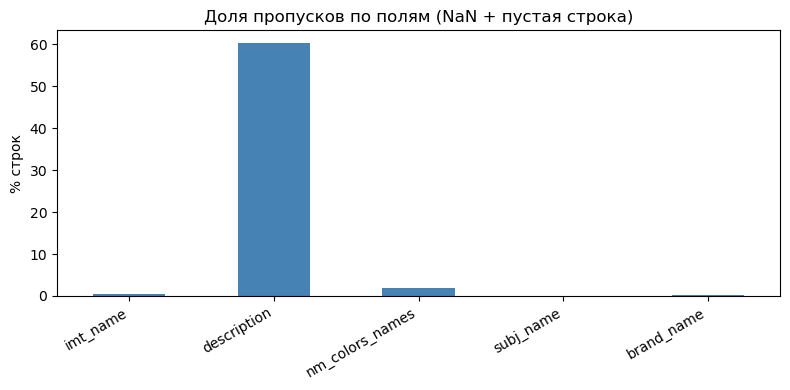


=== subj_root_name внутри отфильтрованного подмножества ===
subj_root_name
Одежда    43316
Обувь     13187
Name: count, dtype: int64

Всего уникальных subj_name: 104

Топ-15 самых частых subj_name:
subj_name
Платья       6998
Футболки     5465
Брюки        3427
Блузки       2342
Костюмы      2317
Туфли        2159
Кроссовки    1835
Джинсы       1746
Рубашки      1689
Юбки         1647
Ботинки      1502
Джемперы     1442
Куртки       1391
Шорты        1240
Босоножки    1205
Name: count, dtype: int64

Самые редкие subj_name (хвост):
subj_name
Шубы чебурашки           13
Дубленки                 12
Топсайдеры               11
Килты банные             10
Мантии                    9
Крестильные комплекты     8
Анораки                   7
Пончо                     6
Шорты пижамные            5
Топы пижамные             4
Крестильные рубашки       2
Косухи                    1
Дафлкоты                  1
Крестильные платья        1
Брюки пижамные            1
Name: count, dtype: int64


In [11]:
# Визуализация 1: доля пропусков по полям
fig, ax = plt.subplots(figsize=(8, 4))
missing_report["total_missing_pct"].plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Доля пропусков по полям (NaN + пустая строка)")
ax.set_ylabel("% строк")
ax.set_xlabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# --- Распределение по категориям ---
print("\n=== subj_root_name внутри отфильтрованного подмножества ===")
print(df_scope["subj_root_name"].value_counts())

subj_name_counts = df_scope["subj_name"].value_counts()
print(f"\nВсего уникальных subj_name: {len(subj_name_counts)}")
print("\nТоп-15 самых частых subj_name:")
print(subj_name_counts.head(15))
print("\nСамые редкие subj_name (хвост):")
print(subj_name_counts.tail(15))



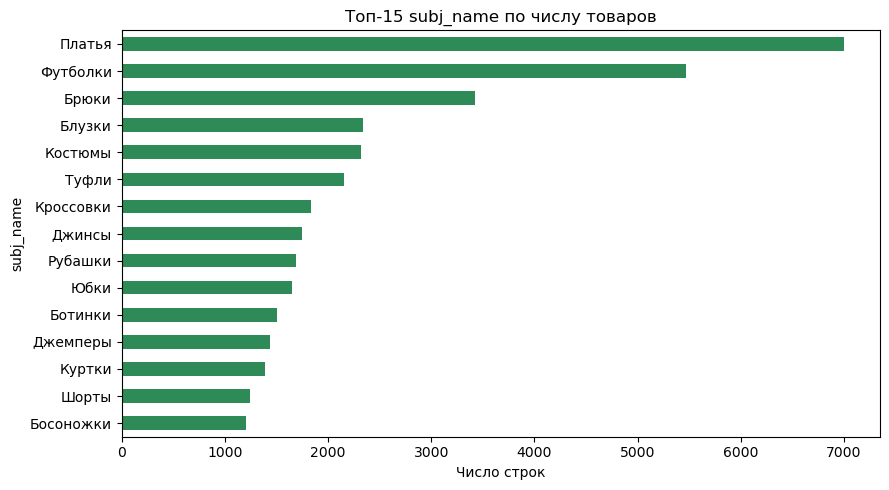


=== Статистика длины imt_name (слова) ===
count    56503.000000
mean         1.999363
std          1.958129
min          0.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         19.000000
Name: imt_name_len_words, dtype: float64

=== Статистика длины description (слова, только непустые) ===
count    22428.000000
mean        64.800874
std         69.131150
min          1.000000
25%         23.000000
50%         42.000000
75%         84.000000
max        704.000000
Name: description_len_words, dtype: float64


In [12]:
# Визуализация 2: топ-15 категорий subj_name
fig, ax = plt.subplots(figsize=(9, 5))
subj_name_counts.head(15).plot(kind="barh", ax=ax, color="seagreen")
ax.invert_yaxis()
ax.set_title("Топ-15 subj_name по числу товаров")
ax.set_xlabel("Число строк")
plt.tight_layout()
plt.show()

# --- Длина текстовых полей ---
df_scope["imt_name_len_words"] = df_scope["imt_name"].fillna("").str.split().str.len()
df_scope["imt_name_len_chars"] = df_scope["imt_name"].fillna("").str.len()
df_scope["description_len_words"] = df_scope["description"].fillna("").str.split().str.len()
df_scope["description_len_chars"] = df_scope["description"].fillna("").str.len()

print("\n=== Статистика длины imt_name (слова) ===")
print(df_scope["imt_name_len_words"].describe())
print("\n=== Статистика длины description (слова, только непустые) ===")
print(df_scope.loc[df_scope["description_len_words"] > 0, "description_len_words"].describe())



In [13]:
# --- Оценка обрезки по лимиту токенов модели (приближённо, на imt_name + description) ---
from sentence_transformers import SentenceTransformer

_tokenizer_check_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
MINILM_MAX_TOKENS = _tokenizer_check_model.get_max_seq_length()
print("Лимит токенов MiniLM:", MINILM_MAX_TOKENS)

approx_product_text = (
    df_scope["imt_name"].fillna("") + " . " + df_scope["description"].fillna("")
).str.strip()

token_counts = approx_product_text.apply(
    lambda t: len(_tokenizer_check_model.tokenizer.encode(t)) if t else 0
)

truncated_share = (token_counts > MINILM_MAX_TOKENS).mean() * 100
print(f"\nДоля карточек, где imt_name+description превышает {MINILM_MAX_TOKENS} токенов "
      f"(и будет обрезано MiniLM): {truncated_share:.1f}%")
print("Это приближённая оценка — финальный product_text соберём на неделе 2, "
      "но уже сейчас видно, что часть длинных описаний будет обрезана.")

del _tokenizer_check_model  # дальше модель грузится заново там, где реально нужна

Token indices sequence length is longer than the specified maximum sequence length for this model (133 > 128). Running this sequence through the model will result in indexing errors


Лимит токенов MiniLM: 128

Доля карточек, где imt_name+description превышает 128 токенов (и будет обрезано MiniLM): 15.0%
Это приближённая оценка — финальный product_text соберём на неделе 2, но уже сейчас видно, что часть длинных описаний будет обрезана.


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Очень хорошо, что пропуски считаются не только как `NaN`, но и как пустые строки: без этого `description` выглядел бы полностью заполненным, а на деле пусто 60% описаний. Длины текста посмотрены отдельно для непустых описаний, найдены выбросы, а проверка «упомянут ли цвет в названии» — нестандартная и полезная идея. Графики аккуратные, с подписями.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Два момента, которые усилят EDA:

1. В отчёт о пропусках не попал `imt_name`, хотя дальше выясняется, что у 113 карточек пусты и название, и описание. Его стоит добавить в `text_cols`.
2. По длинам текстов не хватает вывода про лимит токенов модели. У `paraphrase-multilingual-MiniLM-L12-v2` окно 128 токенов, а у описаний есть хвост до 700 слов. Попробуй оценить, какая доля `product_text` обрезается по лимиту — это готовое обоснование для гипотезы о модели с большим окном (и, как увидишь ниже, это пригодится в эксперименте 1).
</div>

<div class="alert alert-info">
<b> Исправил </b>
</div>

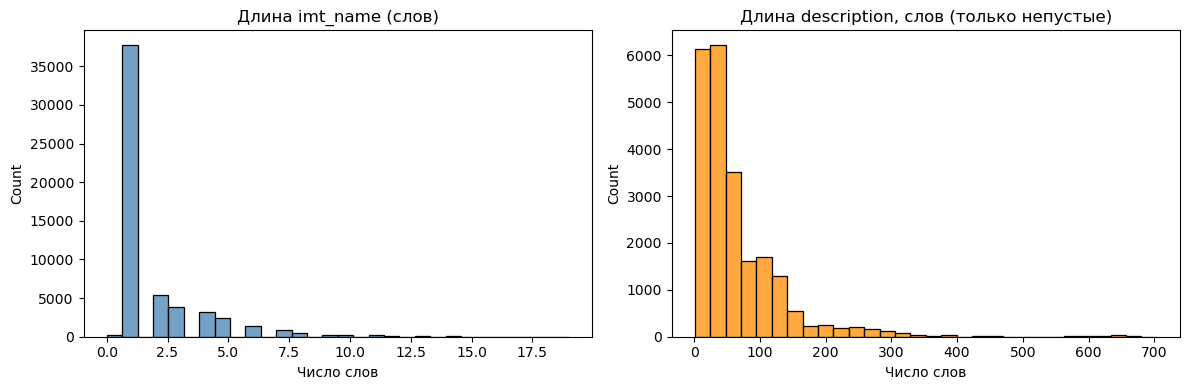


=== Топ-5 самых длинных description (в словах) ===


,imt_id,imt_name,description_len_words
132091,10119657,Туфли кожаные мужские туфли натуральная кожа к...,704
114342,10103313,,699
6237,10005381,Юбка джинсовая,679
129777,10117616,Юбка детская джинсовая мини для девочки летняя...,678
129778,10117616,Юбка детская джинсовая мини для девочки летняя...,678



Уникальных брендов: 3916
Доля строк, где цвет уже упомянут в imt_name: 2.3%


In [14]:
# Визуализация 3: гистограммы длины названия и описания
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_scope["imt_name_len_words"], bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("Длина imt_name (слов)")
axes[0].set_xlabel("Число слов")

desc_nonempty = df_scope.loc[df_scope["description_len_words"] > 0, "description_len_words"]
sns.histplot(desc_nonempty, bins=30, ax=axes[1], color="darkorange")
axes[1].set_title("Длина description, слов (только непустые)")
axes[1].set_xlabel("Число слов")
plt.tight_layout()
plt.show()

# Выбросы: экстремально длинные описания
print("\n=== Топ-5 самых длинных description (в словах) ===")
display(
    df_scope.nlargest(5, "description_len_words")[["imt_id", "imt_name", "description_len_words"]]
)

# --- Бренд и цвет ---
print(f"\nУникальных брендов: {df_scope['brand_name'].nunique()}")

color_in_name = df_scope.apply(
    lambda row: isinstance(row["nm_colors_names"], str)
    and isinstance(row["imt_name"], str)
    and row["nm_colors_names"].lower() in row["imt_name"].lower(),
    axis=1,
)
print(f"Доля строк, где цвет уже упомянут в imt_name: {color_in_name.mean() * 100:.1f}%")

In [15]:
sample_check = df_scope.sample(25, random_state=SEED)[
    ["imt_id", "imt_name", "subj_name", "description", "brand_name", "nm_colors_names"]
]
pd.set_option("display.max_colwidth", 150)
display(sample_check)



,imt_id,imt_name,subj_name,description,brand_name,nm_colors_names
85717,1007705,Сапоги,Сапоги,,Vitacci,черный
73576,10066007,Брюки,Брюки,,KOTON,черный
171326,1015934,Платье,Платья,,Colambetta,"синий, белый"
67663,10060803,Кардиган,Кардиганы,"Важная информация! При заказе изделия, обращайте особое внимание на его параметры, указанные в таблице соответствия. Удлиненный кардиган прямого с...",Velvet Season,бежевый
87795,10078984,Туфли,Туфли,,МЫШОНОК,черный
135770,10127551,Женские брюки,Брюки,,MODERNFECI,бледно-розовый
54495,10048604,Рубашка,Рубашки,,DeFacto,голубой
193603,10178775,Футболка,Футболки,,ТВОЕ,темно-серый
2606,1000231,Пальто,Пальто,,Kling,"черный, красный, оранжевый"
30453,10027497,Босоножки,Босоножки,,Buzoni,бежевый


In [16]:
print("Всего пар «запрос — товар» в train:", len(queries_train))
print("Уникальных query_id в train:", queries_train["query_id"].nunique())

items_per_query = queries_train.groupby("query_id").size()
print("\nЧисло оценённых товаров на один запрос:")
print(items_per_query.describe())

print("\n=== Распределение relevance ===")
relevance_counts = queries_train["relevance"].value_counts().sort_index()
print(relevance_counts)
print("\nДоли:")
print((relevance_counts / len(queries_train) * 100).round(1))



Всего пар «запрос — товар» в train: 11453
Уникальных query_id в train: 700

Число оценённых товаров на один запрос:
count    700.000000
mean      16.361429
std        5.424150
min        1.000000
25%       14.000000
50%       16.000000
75%       19.000000
max       31.000000
dtype: float64

=== Распределение relevance ===
relevance
1    9652
2    1101
3     700
Name: count, dtype: int64

Доли:
relevance
1    84.3
2     9.6
3     6.1
Name: count, dtype: float64


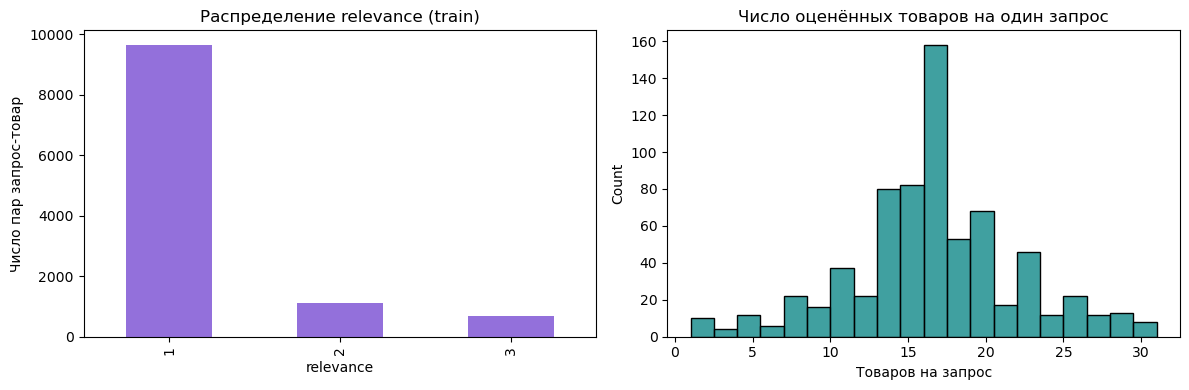

In [17]:
# Визуализация: распределение relevance
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

relevance_counts.plot(kind="bar", ax=axes[0], color="mediumpurple")
axes[0].set_title("Распределение relevance (train)")
axes[0].set_xlabel("relevance")
axes[0].set_ylabel("Число пар запрос-товар")

sns.histplot(items_per_query, bins=20, ax=axes[1], color="teal")
axes[1].set_title("Число оценённых товаров на один запрос")
axes[1].set_xlabel("Товаров на запрос")
plt.tight_layout()
plt.show()



In [18]:
# --- Природа запросов: примеры ---
print("\n=== Случайные примеры query_text ===")
print(queries_train["query_text"].drop_duplicates().sample(10, random_state=SEED).to_list())


=== Случайные примеры query_text ===
['топы cop copine', 'худи mego as', 'бриджи зуавы', 'кожаные мокасины', 'кожаные сабо с открытым мысом', 'классические джинсовые джинсы', 'шубы натуральные на пуговицах', 'тапочки asd', 'тапочки t taccardi', 'кигуруми londe']


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Ручной просмотр карточек, распределение `relevance`, число оценённых товаров на запрос и примеры живых запросов — всё на месте. Особенно ценно, что ты не ограничился цифрами, а посмотрел на сами тексты запросов: наблюдение про «категорию + странный хвост» потом отлично объяснит поведение моделей.
</div>

## Выводы по EDA

**Отбор категорий.** Из 65 корневых категорий выбраны `Одежда` (43 316 строк) и `Обувь` (13 187 строк) — только по ним есть оценки релевантности. После фильтрации: 56 503 строки, 48 489 уникальных `imt_id`, 104 уникальных `subj_name`.

**Пропуски.** Только `description` — системная проблема: пропущено (NaN + пустая строка) 60.3% строк. `nm_colors_names` — 1.8% пропусков, `brand_name` — 0.13%, `subj_name` пропусков не имеет. Раз у 60% товаров нет описания, текст для эмбеддинга у них будет состоять только из названия и категории — это системное свойство каталога, а не редкое исключение.

**Категории.** Топ subj_name — «Платья» (6 998), «Футболки» (5 465), «Брюки» (3 427); хвост распределения — множество subj_name с 1 строкой («Дафлкоты», «Крестильные платья», «Брюки пижамные» и т.п.). Такие редкие категории — кандидаты на особые случаи при оценке: система физически не может показать высокое качество на товаре, у которого в каталоге почти нет аналогов.

**Длина текста.** `imt_name` короткие: медиана 1 слово, среднее ≈2 слова, максимум 19 слов — названия скорее опознавательные («Платье», «Кроссовки»), чем описательные. `description` (только непустые, 22 428 строк) — медиана 42 слова, среднее ≈65, максимум 704 слова (выбросы — вероятно, SEO-тексты или длинные таблицы размеров). Разброс большой (std ≈69), так что шаблон `product_text` должен учитывать возможность как пустого, так и очень длинного описания. Проверка через токенайзер `paraphrase-multilingual-MiniLM-L12-v2` (лимит 128 токенов) показывает: около 15% карточек (по приближению `imt_name`+`description`) превышают лимит и будут обрезаны моделью — это уже сейчас повод рассмотреть на неделе 3 модель с более широким окном контекста.

**Ручная проверка текста (25 карточек).** Явных HTML-тегов не встретилось. Заметны шаблонные вставки не по сути товара — например, предупреждения о размерах («Данная модель обуви … маломерит», «При заказе изделия обращайте внимание…») в начале `description`, что размывает смысловое ядро текста. Заметно совпадение `subj_name` с общим словом в `imt_name` (например, `imt_name = "Сапоги"`, `subj_name = "Сапоги"`) — в таких случаях название несёт мало уникальной информации.

**Бренд и цвет.** 3 916 уникальных брендов — само по себе это не доказывает, что бренд «избыточен» для текста; скорее показывает, что бренд работает как точный идентификатор (имя собственное), который эмбеддингу сложно осмысленно связать со значением, а не как смысловая характеристика товара. Поэтому решение не включать бренд в `product_text` оправдано именно природой этого поля, а не количеством уникальных значений (и, забегая вперёд: в разборе ошибок окажется, что запросы с брендом — главный источник промахов семантического поиска). Цвет упомянут в `imt_name` только у 2.3% строк — значит, `nm_colors_names` несёт **новую** информацию, которой нет в названии. Это, наоборот, аргумент **за** включение цвета в текст для эмбеддинга — в отличие от бренда, цвет не дублирует уже существующий отдельный признак, а добавляет уникальный смысл.

**Разметка (train).** 11 453 пары «запрос-товар», 700 уникальных запросов, в среднем ≈16 оценённых товаров на запрос (от 1 до 31) — это верхняя граница для Precision@K/Recall@K при интерпретации метрик.

**Распределение relevance.** Только положительные оценки: 1 — 84.3%, 2 — 9.6%, 3 — 6.1%. **Оценки 0 в разметке отсутствуют вовсе** — значит, весь `relevance = 0` в оценке качества будет появляться только за счёт товаров, не попавших в разметку конкретного запроса (по правилу методики «не в разметке → нерелевантно»). Это стоит явно зафиксировать: без этого правила метрики посчитать вообще нельзя, разметка сама по себе не содержит отрицательных примеров.

**Природа запросов.** Примеры (`топы cop copine`, `худи mego as`, `тапочки asd`, `тапочки t taccardi`) показывают, что часть синтетических запросов выглядит как категория + странный «хвост» (обрывок бренда/шума), а не как естественный пользовательский запрос. Это стоит учитывать при интерпретации ошибок семантического поиска — модель может законно не находить соответствие для шумных «хвостов», и такие случаи не всегда говорят о слабости самого подхода.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Выводы по EDA — одни из самых сильных, что я видел в этом проекте. Каждое утверждение опирается на цифру из анализа. Очень точное наблюдение, что в разметке **нет ни одной оценки 0** и все нули в метриках появятся только из правила «не в разметке → нерелевантно». Это понимание напрямую влияет на интерпретацию метрик, и ты его сформулировал заранее.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Посмотри ещё раз на аргументацию по бренду и цвету — сейчас она немного противоречит самим данным:

- 3 916 уникальных брендов сами по себе не доказывают, что бренд «избыточен» для текста. Это скорее говорит о том, что бренд — точный идентификатор, который эмбеддингу сложно «понять». Кстати, в разделе 4.2 запросы с брендом окажутся главным источником ошибок, так что к этому решению стоит вернуться.
- Цвет упомянут в названии всего у 2.3% строк — значит, `nm_colors_names` несёт **новую** информацию, которой нет в названии. Это аргумент скорее за включение цвета, а в `build_product_text` он используется как аргумент против. Подумай, как сформулировать решение так, чтобы вывод следовал из цифры.
</div>

<div class="alert alert-info">
<b> Исправил </b>
</div>

---

## Неделя 2 — базовый пайплайн и оценка качества

**Цель:** оперевшись на результаты EDA, создать работающий поиск и получить первые метрики качества.

Прежде чем реализовывать семантический поиск, основанный на эмбеддингах, нужно проверить, как справляется более простая модель, опирающаяся на TF-IDF. Простая модель нужна как baseline, без этой точки отсчёта результат невозможно интерпретировать.


### 1. Подготовка данных


Реализуйте решения недели 1:

1. Отфильтруйте выбранные категории.
2. Дедуплицируйте строки по `imt_id`. Сформулируйте правило, по которому будете определять, какую строку оставить. К примеру, можете оставить строку с самым информативным описанием. Ответ обоснуйте.
3. Отбросьте карточки, у которых пусты одновременно и `imt_name`, и `description`.
4. Напишите функцию очистки текста.
5. Соберите единый текст карточек в отдельной колонке `product_text`.

In [19]:
labeled_item_ids = train_item_ids | test_item_ids
labeled_root_categories = df_raw.loc[df_raw["imt_id"].isin(labeled_item_ids), "subj_root_name"].value_counts()
print("\nКорневые категории размеченных item_id (train+test):")
print(labeled_root_categories)

missing_labeled = labeled_item_ids - set(df_scope["imt_id"])
assert not missing_labeled, f"{len(missing_labeled)} размеченных item_id потеряно при фильтрации"




Корневые категории размеченных item_id (train+test):
subj_root_name
Одежда    2328
Обувь      757
Name: count, dtype: int64


In [20]:
df_scope["_description_len"] = df_scope["description"].fillna("").str.len()

df_dedup = (
    df_scope.sort_values(["_description_len", "nm_id"], ascending=[False, True])
    .drop_duplicates(subset="imt_id", keep="first")
    .drop(columns="_description_len")
    .reset_index(drop=True)
)

missing_after_dedup = labeled_item_ids - set(df_dedup["imt_id"])
assert not missing_after_dedup, f"{len(missing_after_dedup)} размеченных item_id потеряно после дедупликации"


In [21]:
# --- 3. Отсев карточек без текста (пусты и imt_name, и description) ---
imt_name_empty = df_dedup["imt_name"].isna() | (df_dedup["imt_name"] == "")
description_empty = df_dedup["description"].isna() | (df_dedup["description"] == "")
both_empty = imt_name_empty & description_empty

print(f"\nКарточек с пустыми и imt_name, и description: {both_empty.sum()}")

df_clean = df_dedup[~both_empty].reset_index(drop=True)
print(f"После отсева: {len(df_clean)} строк (было {len(df_dedup)})")

# Проверка: отсев карточек без текста не должен затрагивать размеченные товары
missing_after_drop = labeled_item_ids - set(df_clean["imt_id"])
assert not missing_after_drop, f"{len(missing_after_drop)} размеченных item_id потеряно после отсева пустых карточек"
print(f"Проверено: все {len(labeled_item_ids)} размеченных item_id остались в df_clean")



Карточек с пустыми и imt_name, и description: 113
После отсева: 48376 строк (было 48489)
Проверено: все 2580 размеченных item_id остались в df_clean


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Правило дедупликации сформулировано явно и обосновано: строка с самым длинным описанием — самая информативная для эмбеддинга. Отсев сделан ровно по условию — только карточки, где пусты **одновременно** название и описание; товары без описания сохранены, и это правильно.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> У многих артикулов одной карточки описания одинаковой длины (часто все пустые), а `sort_values` по умолчанию использует нестабильную сортировку. В таких случаях какая строка останется — дело случая, и при перезапуске каталог может немного отличаться. Добавь второй ключ сортировки (например, `nm_id`), чтобы правило стало детерминированным. И после каждого шага подготовки полезно ставить `assert`, что размеченные товары не потерялись.
</div>

<div class="alert alert-info">
<b> Исправил </b>
</div>

In [22]:
# --- 4. Функция очистки текста ---
# Шаблонные фразы не по сути товара, найденные при ручном просмотре карточек
# (недели 1): предупреждения о размерах, отсылки к таблицам соответствия.
BOILERPLATE_PATTERNS = [
    r"[^.!?]*маломерит[^.!?]*[.!?]?",
    r"[^.!?]*таблиц[а-я]* (размеров|соответствия)[^.!?]*[.!?]?",
    r"[^.!?]*обращайте (особое )?внимание[^.!?]*[.!?]?",
    r"важная информация!?",
]
BOILERPLATE_RE = re.compile("|".join(BOILERPLATE_PATTERNS), flags=re.IGNORECASE)

HTML_TAG_RE = re.compile(r"<[^>]+>")
MULTI_SPACE_RE = re.compile(r"\s+")


def clean_text(text) -> str:
    """Очищает текст карточки от HTML-тегов, шаблонных вставок и лишних пробелов."""
    if not isinstance(text, str) or not text.strip():
        return ""

    text = HTML_TAG_RE.sub(" ", text)
    text = BOILERPLATE_RE.sub(" ", text)
    text = MULTI_SPACE_RE.sub(" ", text).strip()
    return text


# Сначала измеряем эффект на всех непустых description, а не на случайной выборке —
# так эффект очистки становится измеримым, а не "на глаз"
nonempty_desc = df_clean["description"].dropna()
nonempty_desc = nonempty_desc[nonempty_desc.str.strip() != ""]

had_boilerplate = nonempty_desc.apply(lambda t: bool(BOILERPLATE_RE.search(t)))
print(f"Доля непустых description с шаблонными вставками (регулярки сработали): "
      f"{had_boilerplate.mean()*100:.1f}% ({had_boilerplate.sum()} из {len(nonempty_desc)})")

# Демонстрация на примерах, где регулярки действительно сработали.
# Без срезов [:200] — иначе совпадение, произошедшее позже в строке, незаметно
# прячется, и "ДО"/"ПОСЛЕ" выглядят одинаковыми, хотя на деле отличаются.
changed_examples = nonempty_desc[had_boilerplate].sample(min(5, had_boilerplate.sum()), random_state=SEED)
n_emptied = 0
for sample in changed_examples:
    cleaned = clean_text(sample)
    if cleaned == "":
        n_emptied += 1
    print("ДО:  ", sample)
    print("ПОСЛЕ:", cleaned)
    print()

print(
    f"Из {len(changed_examples)} показанных примеров {n_emptied} стали пустыми после очистки — "
    f"это описания, состоявшие целиком из шаблонной вставки без собственной информации о товаре. "
    f"Это ожидаемо: пустые поля дальше пропускаются при сборке product_text, товар не теряется."
)

df_clean["imt_name_clean"] = df_clean["imt_name"].apply(clean_text)
df_clean["description_clean"] = df_clean["description"].apply(clean_text)



Доля непустых description с шаблонными вставками (регулярки сработали): 2.7% (489 из 18087)
ДО:   Модель МОЖЕТ МАЛОМЕРИТЬ НА ОДИН РАЗМЕР, в зависимости от особенностей Вашей ноги!
ПОСЛЕ: 

ДО:   В комбинированном жакете в меру и строгости, и женственности. Если за первое отвечает классический приталенный крой и однотонность цвета. То за второе - элементы кружева и изящный воротник. Данную модель можно надеть в офис, на учёбу и даже на свидание-она сделает образ утончённым. Рукав полной длины, подчёркнутый шёлковым манжетом. Завершающий штрих придают мелкие пуговички из камней, которые элегантно расположены на планке, обрамлённой шёлком. Модель с подплечниками. Длина блузки по спинке - 55 см. Нарядная праздничная блузка подойдет для женщин среднего роста, для высоких и для невысоких. Классическая блузка с рукавом 7/8 подойдет как для работы в офисе (dress code), так и для прогулок, также ее можно надеть на любой праздник, свадьбу, отлично впишется в офисный и вечерний стиль. ***Чтобы то

In [23]:
PRODUCT_TEXT_TEMPLATE = "imt_name_clean + subj_name + description_clean + nm_colors_names"

# --- 5-6. Сборка product_text ---
def build_product_text(row) -> str:
    """
    Шаблон: imt_name + subj_name + description + nm_colors_names.
    Бренд не включаем (решение с QA-сессии: бренд не должен влиять на
    семантическую выдачу — это точный идентификатор, а не смысловая характеристика).
    Цвет, наоборот, включаем: он упомянут в imt_name лишь у 2.3% строк, то есть
    nm_colors_names несёт новую информацию, которой обычно нет в названии
    (см. исправленный вывод EDA — эта же цифра раньше ошибочно использовалась
    как аргумент против включения цвета).
    Явный разделитель " . " между полями, пустые поля пропускаются.
    """
    parts = [
        row["imt_name_clean"],
        row["subj_name"] if isinstance(row["subj_name"], str) else "",
        row["description_clean"],
        row["nm_colors_names"] if isinstance(row["nm_colors_names"], str) else "",
    ]
    parts = [p.strip() for p in parts if isinstance(p, str) and p.strip()]
    return " . ".join(parts)


df_clean["product_text"] = df_clean.apply(build_product_text, axis=1)

print(f"\nИтоговый каталог: {len(df_clean)} строк")
print(f"Пустых product_text: {(df_clean['product_text'] == '').sum()}")

# Проверка вручную на 5-10 примерах
display(df_clean[["imt_id", "imt_name", "subj_name", "nm_colors_names", "product_text"]].sample(8, random_state=SEED))


Итоговый каталог: 48376 строк
Пустых product_text: 0


,imt_id,imt_name,subj_name,nm_colors_names,product_text
47215,10169040,Джинсы женские 04J,Джинсы,синий,Джинсы женские 04J . Джинсы . синий
6467,10016370,Брюки женские,Брюки,черный,"Брюки женские . Брюки . Брюки-джоггеры на кулиске гарантируют максимальный комфорт. Они идеально впишутся не только в повседневный образ, но и под..."
43348,10130324,Джемпер,Джемперы,серый,Джемпер . Джемперы . серый
48236,10179358,"Футболка ""RAY""",Футболки,черный,"Футболка ""RAY"" . Футболки . черный"
15302,10048000,Брюки спортивные женские/,Брюки,морковный,"Брюки спортивные женские/ . Брюки . На фотографии параметры модели: рост 160 см, размер 42/XS. Длина по внутреннему шву 71 см. Внешняя длина 99 см..."
33752,10035280,Кроссовки,Кроссовки,черный,Кроссовки . Кроссовки . черный
46722,10164302,Свитшот,Свитшоты,бордовый,Свитшот . Свитшоты . бордовый
38335,10070063,Босоножки,Босоножки,розовый,Босоножки . Босоножки . розовый


**Подготовка данных — результат.**

- После фильтрации категорий (Одежда + Обувь): 56 503 строки, 48 489 уникальных `imt_id`.
- Дедупликация по `imt_id` (правило: оставляем строку с самым длинным `description`): удалено 8 014 дублей-артикулов, итог — 48 489 строк (одна на карточку).
- Отсев карточек без текста (пусты и `imt_name`, и `description`): удалено 113 строк.
- Итоговый рабочий каталог: **48 376 карточек**, пустых `product_text` — 0.
- Шаблон `product_text`: `imt_name + subj_name + description + nm_colors_names` (после очистки), разделитель `" . "`, пустые поля пропускаются. Бренд не включён (не должен влиять на семантическую выдачу — точный идентификатор, а не смысловая характеристика); цвет включён (в `imt_name` упомянут лишь у 2.3% строк — несёт новую информацию, см. исправленный вывод EDA).

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Здесь мне особенно понравилось, что очистка текста построена на **конкретных находках из EDA**: шаблонные предупреждения про «маломерит», таблицы размеров и «обращайте внимание» — это именно то, что размывает смысл карточки. Многие ограничиваются удалением спецсимволов, а у тебя очистка обоснована данными. `product_text` собран аккуратно: явный разделитель, пустые поля пропускаются, пустых текстов в итоге 0.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Демонстрация работы `clean_text` получилась не очень показательной: три из пяти случайных описаний пустые, а в оставшихся двух шаблонных фраз нет, поэтому «ДО» и «ПОСЛЕ» совпадают. Возьми примеры, где регулярки действительно срабатывают, и посчитай, у какой доли описаний что-то было вырезано — так эффект очистки станет измеримым, а заодно ты убедишься, что регулярки не съедают полезные предложения целиком.
</div>

<div class="alert alert-info">
<b> Исправил </b>
</div>

### Каталог для поиска и оценки

1. Посчитайте метрику при поиске по всему отфильтрованному каталогу. Например, вычислите NDCG@10 лексическим поиском на 100 запросах.
2. Выведите топ-10 для одного запроса и отметьте, какие товары есть в разметке, а каких нет. Выясните, в чём проблема.
3. Ограничьте каталог оценки пулом асессоров: возьмите из `wb_products_dedup.parquet` только список `imt_id` и оставьте в своём подготовленном каталоге пересечение с ним. Тексты и все признаки — ваши, из шага 1.
4. Пересчитайте метрику и сравните результаты.
5. Посмотрите на распределение `relevance` и число оценённых товаров на запрос. Проверьте, у всех ли запросов есть товары с `relevance` ≥ 2.

In [24]:
# --- Подготовка golden-сета из train ---
# Формат: query_id -> {"text": ..., "labels": {item_id: relevance, ...}}
golden_set = {}
for qid, group in queries_train.groupby("query_id"):
    golden_set[qid] = {
        "text": group["query_text"].iloc[0],
        "labels": dict(zip(group["item_id"], group["relevance"])),
    }

print(f"Всего запросов в golden-сете: {len(golden_set)}")


def ndcg_at_k(ranked_item_ids, labels: dict, k: int = 10) -> float:
    """NDCG@k по полной шкале relevance (0-3), gain = 2^rel - 1."""
    dcg = 0.0
    for i, item_id in enumerate(ranked_item_ids[:k]):
        rel = labels.get(item_id, 0)
        gain = (2 ** rel) - 1
        dcg += gain / np.log2(i + 2)  # позиции с 1, log2(1+1)=1

    ideal_rels = sorted(labels.values(), reverse=True)[:k]
    idcg = sum(((2 ** rel) - 1) / np.log2(i + 2) for i, rel in enumerate(ideal_rels))

    return dcg / idcg if idcg > 0 else 0.0


def build_tfidf_index(catalog_df: pd.DataFrame):
    vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=50_000)
    matrix = vectorizer.fit_transform(catalog_df["product_text"])
    return vectorizer, matrix


def quick_lexical_search(query_text: str, catalog_df: pd.DataFrame, vectorizer, matrix, top_k: int = 10):
    query_vec = vectorizer.transform([query_text])
    scores = (matrix @ query_vec.T).toarray().ravel()

    # Тот же детерминированный tie-break, что и в search_lexical/search_semantic:
    # при равных score (например, когда совпадений нет вовсе) np.argsort не
    # гарантирует порядок, что сделало бы выдачу невоспроизводимой.
    imt_ids = catalog_df["imt_id"].to_numpy()
    order = np.lexsort((imt_ids, -scores))
    top_idx = order[:top_k]

    return catalog_df["imt_id"].values[top_idx], scores[top_idx]

Всего запросов в golden-сете: 700


In [25]:
# Метрика при поиске по всему отфильтрованному каталогу 
vectorizer_full, matrix_full = build_tfidf_index(df_clean)

sample_query_ids = np.random.RandomState(SEED).choice(
    list(golden_set.keys()), size=100, replace=False
)

ndcg_scores_full = []
for qid in sample_query_ids:
    q = golden_set[qid]
    ranked_ids, _ = quick_lexical_search(q["text"], df_clean, vectorizer_full, matrix_full, top_k=10)
    ndcg_scores_full.append(ndcg_at_k(ranked_ids, q["labels"], k=10))

print(f"\nNDCG@10 (лексический поиск, весь каталог {len(df_clean)} товаров, 100 запросов): "
      f"{np.mean(ndcg_scores_full):.4f}")





NDCG@10 (лексический поиск, весь каталог 48376 товаров, 100 запросов): 0.0436


In [26]:
# Топ-10 для одного запроса — что размечено, а что нет 
example_qid = sample_query_ids[0]
example_q = golden_set[example_qid]
ranked_ids, ranked_scores = quick_lexical_search(
    example_q["text"], df_clean, vectorizer_full, matrix_full, top_k=10
)

print(f"\n=== Пример: запрос «{example_q['text']}» (query_id={example_qid}) ===")
for item_id, score in zip(ranked_ids, ranked_scores):
    in_labels = item_id in example_q["labels"]
    rel = example_q["labels"].get(item_id, "—")
    name = df_clean.loc[df_clean["imt_id"] == item_id, "imt_name"].values
    name = name[0] if len(name) else "?"
    print(f"  imt_id={item_id:>10} score={score:.3f} "
          f"{'В РАЗМЕТКЕ (rel=' + str(rel) + ')' if in_labels else 'нет в разметке':<25} {name}")

n_in_labels = sum(1 for i in ranked_ids if i in example_q["labels"])
print(f"\nИз топ-10: {n_in_labels} товаров есть в разметке этого запроса, "
      f"{10 - n_in_labels} — нет.")
print("Диагноз: поиск идёт по всему каталогу (48k+ карточек), а асессоры оценивали")
print("только пул из wb_products_dedup.parquet (несколько тысяч карточек). Система")
print("может найти вполне разумный товар, которого асессоры просто не видели —")
print("и такой товар засчитывается нерелевантным, хотя мог бы быть релевантным.")





=== Пример: запрос «топы cop copine» (query_id=SYN_000210) ===
  imt_id=  10133185 score=0.713 нет в разметке            Топы
  imt_id=  10067786 score=0.665 нет в разметке            Топы
  imt_id=  10133186 score=0.665 нет в разметке            Топы
  imt_id=  10124446 score=0.661 нет в разметке            Топы
  imt_id=  10016977 score=0.652 В РАЗМЕТКЕ (rel=1)        Топы
  imt_id=  10133188 score=0.652 нет в разметке            Топы
  imt_id=  10016979 score=0.629 нет в разметке            Топы
  imt_id=  10016976 score=0.629 нет в разметке            Топы
  imt_id=  10016978 score=0.625 нет в разметке            Топы
  imt_id=  10133187 score=0.625 нет в разметке            Топы

Из топ-10: 1 товаров есть в разметке этого запроса, 9 — нет.
Диагноз: поиск идёт по всему каталогу (48k+ карточек), а асессоры оценивали
только пул из wb_products_dedup.parquet (несколько тысяч карточек). Система
может найти вполне разумный товар, которого асессоры просто не видели —
и такой товар засчит

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Отличный разбор: метрика на полном каталоге посчитана, на конкретном запросе показано, что выдача содержательно адекватна, но ни один товар из топ-10 не размечен. Диагноз сформулирован верно — проблема не в поиске, а в том, что асессоры видели только фиксированный пул.
</div>

In [27]:

# Ограничение каталога пулом асессоров
df_dedup_pool = pd.read_parquet(ASSESSED_POOL_PATH, engine="fastparquet")
dedup_ids = set(df_dedup_pool["imt_id"])

print(f"\nКарточек в пуле асессоров (wb_products_dedup): {len(dedup_ids)}")

df_catalog_eval = df_clean[df_clean["imt_id"].isin(dedup_ids)].reset_index(drop=True)
print(f"Пересечение с нашим подготовленным каталогом: {len(df_catalog_eval)} карточек "
      f"(из {len(df_clean)})")

# Сколько карточек пула реально привязаны хотя бы к одному запросу (упоминается в выводах
# 4.3 как "2 580 из 4 256") — считаем явно, а не оставляем как число "из головы".
pool_linked_to_queries = dedup_ids & labeled_item_ids
print(
    f"Карточек пула, привязанных хотя бы к одному запросу (train+test): "
    f"{len(pool_linked_to_queries)} из {len(dedup_ids)} "
    f"({len(pool_linked_to_queries) / len(dedup_ids) * 100:.1f}%)"
)




Карточек в пуле асессоров (wb_products_dedup): 4256
Пересечение с нашим подготовленным каталогом: 4256 карточек (из 48376)
Карточек пула, привязанных хотя бы к одному запросу (train+test): 2580 из 4256 (60.6%)


In [28]:
# Пересчёт метрики на ограниченном каталоге ===
vectorizer_eval, matrix_eval = build_tfidf_index(df_catalog_eval)

ndcg_scores_eval = []
for qid in sample_query_ids:
    q = golden_set[qid]
    ranked_ids, _ = quick_lexical_search(q["text"], df_catalog_eval, vectorizer_eval, matrix_eval, top_k=10)
    ndcg_scores_eval.append(ndcg_at_k(ranked_ids, q["labels"], k=10))

print(f"\nNDCG@10 (лексический поиск, каталог оценки {len(df_catalog_eval)} товаров, "
      f"те же 100 запросов): {np.mean(ndcg_scores_eval):.4f}")
print(f"Было (весь каталог): {np.mean(ndcg_scores_full):.4f}")
print(f"Разница: {np.mean(ndcg_scores_eval) - np.mean(ndcg_scores_full):+.4f}")





NDCG@10 (лексический поиск, каталог оценки 4256 товаров, те же 100 запросов): 0.4607
Было (весь каталог): 0.0436
Разница: +0.4171


In [29]:
# Распределение relevance и покрытие релевантными товарами 
all_relevances = [rel for q in golden_set.values() for rel in q["labels"].values()]
print("\n=== Распределение relevance по всем запросам golden-сета ===")
print(pd.Series(all_relevances).value_counts().sort_index())

queries_without_high_rel = [
    qid for qid, q in golden_set.items()
    if not any(rel >= 2 for rel in q["labels"].values())
]
print(f"\nЗапросов без товаров с relevance >= 2: {len(queries_without_high_rel)} "
      f"из {len(golden_set)} ({len(queries_without_high_rel) / len(golden_set) * 100:.1f}%)")


=== Распределение relevance по всем запросам golden-сета ===
1    9652
2    1101
3     700
Name: count, dtype: int64

Запросов без товаров с relevance >= 2: 0 из 700 (0.0%)


**Каталог для поиска и оценки — результат.**

- **NDCG@10 на всём подготовленном каталоге (48 376 товаров):** 

0.0436 — крайне низкое значение.

- **Диагностика на примере запроса «топы cop copine».** 

Топ-10 лексического поиска — все товары категории «Топы»/близкие, то есть выдача содержательно адекватна, но только **1 из 10** есть в разметке этого запроса (relevance=1, то есть лишь частично подходящий). Проблема не в качестве поиска, а в масштабе каталога: асессоры размечали не весь каталог, а фиксированный пул (`wb_products_dedup.parquet`), и система стабильно находит разумные, но по большей части неразмеченные товары — они засчитываются нерелевантными, хотя могли бы быть в топе у асессоров.

- **Пул асессоров:** 4 256 карточек, все они полностью входят в наш подготовленный каталог (пересечение = 4 256 из 4 256) — потерь на этапе фильтрации/дедупликации нет.

- **NDCG@10 на каталоге оценки (4 256 товаров):** 0.4607 — прирост **+0.4171** относительно поиска по всему каталогу. Разница подтверждает: оценка должна идти строго по каталогу асессоров (`wb_products_dedup`), а не по всему подготовленному каталогу — иначе метрики искусственно занижены и не отражают реальное качество системы.

- **Распределение relevance** по всей разметке (700 запросов): 1 — 9 652 (84.3%), 2 — 1 101 (9.6%), 3 — 700 (6.1%) — совпадает с тем, что видели на train при EDA.

- **Покрытие сильно релевантными товарами:** у **всех 700 запросов (100%)** есть хотя бы один товар с `relevance ≥ 2`. Это хорошая новость для дальнейшей оценки — ни один запрос не придётся исключать из-за отсутствия «правильного» ответа.

**Вывод:** дальше метрики считаем **только по ограниченному каталогу оценки** (`df_catalog_eval`, 4 256 карточек), а не по всему подготовленному каталогу.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Каталог оценки собран правильно: из файла пула взяты только `imt_id`, а тексты и признаки — свои, из подготовки. Пересечение 4 256 из 4 256 подтверждает, что при фильтрации и дедупликации ничего не потерялось. Сравнение 0.058 → 0.444 убедительно показывает, почему считать метрики нужно именно по пулу. Проверка, что у всех запросов есть товары с `relevance ≥ 2`, тоже на месте.
</div>

### 2. Модели поиска

Реализуйте два поисковых движка с одинаковым интерфейсом. Это позволит прогнать оба через одну функцию оценки:

In [30]:

def search_lexical(query: str, top_k: int = 10) -> pd.DataFrame:
    """Возвращает top_k товаров с колонками imt_id, imt_name, subj_name, score.
    Поиск идёт по каталогу оценки (df_catalog_eval), TF-IDF + косинусная близость.
    """
    query_clean = clean_text(query)
    query_vec = vectorizer_eval.transform([query_clean])
    scores = (matrix_eval @ query_vec.T).toarray().ravel()

    # Детерминированный tie-break: при равных score (частый случай, например когда
    # совпадений нет вовсе) np.argsort не гарантирует порядок — топ-K мог бы "плавать"
    # между запусками. np.lexsort: сначала по -scores (убывание), при равенстве — по imt_id.
    imt_ids = df_catalog_eval["imt_id"].to_numpy()
    order = np.lexsort((imt_ids, -scores))
    top_idx = order[:top_k]

    result = df_catalog_eval.iloc[top_idx][["imt_id", "imt_name", "subj_name"]].copy()
    result["score"] = scores[top_idx]
    return result.reset_index(drop=True)


Реализуйте лексический baseline на TF-IDF:

In [31]:
# Ручная проверка на нескольких запросах
for q in ["удобные кроссовки для бега", "черное платье на выпускной", "теплая куртка зимняя"]:
    print(f"\n=== Запрос: «{q}» ===")
    display(search_lexical(q, top_k=5))


=== Запрос: «удобные кроссовки для бега» ===


,imt_id,imt_name,subj_name,score
0,10007042,Кроссовки Vs Pace,Кроссовки,0.256137
1,10024390,Кроссовки,Кроссовки,0.228341
2,1000379,Кроссовки,Кроссовки,0.198988
3,10152002,Кроссовки 527,Кроссовки,0.193278
4,10152011,Кроссовки Roav,Кроссовки,0.185372



=== Запрос: «черное платье на выпускной» ===


,imt_id,imt_name,subj_name,score
0,10039083,Платье,Платья,0.256325
1,10003710,"Сарафан / Женское офисное короткое платье, большие размеры, для дома, повседневное, трикотажное",Сарафаны,0.206596
2,10003711,"Женское вечернее офисное короткое платье, большие размеры, праздничное, повседневное, трикотажное",Платья,0.204719
3,10003713,"Женское вечернее офисное короткое платье, большие размеры, праздничное, повседневное, трикотажное",Платья,0.204525
4,10149677,Сарафан,Сарафаны,0.200966



=== Запрос: «теплая куртка зимняя» ===


,imt_id,imt_name,subj_name,score
0,10000525,Зимняя флисовая куртка,Куртки,0.334062
1,10034209,Куртка,Кофты,0.272393
2,10056767,Куртка,Куртки,0.240164
3,10085277,Куртка,Куртки,0.232383
4,1014110,Куртка,Куртки,0.190093


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Интерфейс поиска единый (`query`, `top_k` → DataFrame с `imt_id`, `imt_name`, `subj_name`, `score`), запрос проходит ту же очистку, что и карточки. Скалярное произведение вместо `cosine_similarity` — корректный и более быстрый вариант, потому что строки TF-IDF уже L2-нормированы.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Обрати внимание на выдачу по запросу «удобные кроссовки для бега»: у всех пяти товаров одинаковый score `0.260909`. При равных скорах `np.argsort` не гарантирует порядок, поэтому состав топ-10 может «плавать» между запусками и даже между методами, а вместе с ним и метрики. Добавь детерминированный tie-break — например, вторым ключом сортировать по `imt_id` через `np.lexsort`.
</div>

Реализуйте семантический поиск:

<div class="alert alert-info">
<b> Исправил </b>
</div>

In [32]:
for f in ["catalog_embeddings.npy", "catalog_embeddings_e5.npy"]:
    if os.path.exists(f):
        os.remove(f)
        print(f"Удалён кэш: {f}")

Удалён кэш: catalog_embeddings.npy
Удалён кэш: catalog_embeddings_e5.npy


In [33]:
# Модель: мультиязычная, с поддержкой русского, компактная для MVP.
# paraphrase-multilingual-MiniLM-L12-v2: 118M параметров, лимит 128 токенов,
EMBEDDING_MODEL_NAME = "paraphrase-multilingual-MiniLM-L12-v2"
embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)

print("Максимальная длина входа модели (токенов):", embedding_model.max_seq_length)

CATALOG_EMBEDDINGS_PATH = "catalog_embeddings.npy"

if os.path.exists(CATALOG_EMBEDDINGS_PATH):
    catalog_embeddings = np.load(CATALOG_EMBEDDINGS_PATH)
    print(f"Эмбеддинги загружены с диска: {catalog_embeddings.shape}")
else:
    catalog_embeddings = embedding_model.encode(
        df_catalog_eval["product_text"].tolist(),
        batch_size=64,
        show_progress_bar=True,
        normalize_embeddings=True,
    )
    np.save(CATALOG_EMBEDDINGS_PATH, catalog_embeddings)
    print(f"Эмбеддинги посчитаны и сохранены: {catalog_embeddings.shape}")


def search_semantic(query: str, top_k: int = 10) -> pd.DataFrame:
    """Возвращает top_k товаров с колонками imt_id, imt_name, subj_name, score.
    Поиск по каталогу оценки (df_catalog_eval), эмбеддинги той же модели.
    """
    query_clean = clean_text(query)
    query_embedding = embedding_model.encode([query_clean], normalize_embeddings=True)
    scores = catalog_embeddings @ query_embedding[0]

    imt_ids = df_catalog_eval["imt_id"].to_numpy()
    order = np.lexsort((imt_ids, -scores))
    top_idx = order[:top_k]

    result = df_catalog_eval.iloc[top_idx][["imt_id", "imt_name", "subj_name"]].copy()
    result["score"] = scores[top_idx]
    return result.reset_index(drop=True)


for q in ["удобные кроссовки для бега", "черное платье на выпускной", "теплая куртка зимняя"]:
    print(f"\n=== Запрос: «{q}» ===")
    display(search_semantic(q, top_k=5))

Максимальная длина входа модели (токенов): 128


Batches: 100%|██████████| 67/67 [00:17<00:00,  3.92it/s]


Эмбеддинги посчитаны и сохранены: (4256, 384)

=== Запрос: «удобные кроссовки для бега» ===


,imt_id,imt_name,subj_name,score
0,10109654,Кеды кожаные туфли повседневные 201707-4-1101,Полуботинки,0.819764
1,10109653,Кеды кожаные классические 201707-3-1301,Полуботинки,0.817878
2,10109648,Полуботинки кожаные туфли классические 201702-4-1101,Полуботинки,0.810388
3,10109662,Кроссовки кожаные повседневные 201725-1-1101,Полуботинки,0.810095
4,10036445,Кроссовки,Кроссовки,0.806987



=== Запрос: «черное платье на выпускной» ===


,imt_id,imt_name,subj_name,score
0,10021603,Двухстороннее платье с эффектом бандажа,Платья,0.782538
1,10057861,Корсетное платье,Платья,0.754152
2,10173477,"Элегантное летнее платье, декорировано шнуровкой и воланами",Платья,0.738315
3,10021109,Платье из шифона Горох,Платья,0.725355
4,10032022,Платье с расклешенной юбкой,Платья,0.714077



=== Запрос: «теплая куртка зимняя» ===


,imt_id,imt_name,subj_name,score
0,10000525,Зимняя флисовая куртка,Куртки,0.883244
1,10063797,Костюм зимний для девочки/Детский утеплённые костюм/Детский мембранный костюм,Костюмы,0.821923
2,10067910,Стеганое пальто,Пальто,0.812841
3,1011053,Пальто,Пальто,0.773767
4,1009324,Куртка,Куртки,0.755585


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Семантический поиск реализован чисто: эмбеддинги нормированы, считаются батчами и кешируются на диск, а лимит модели в 128 токенов выведен явно. Интерфейс совпадает с лексическим — значит, оба движка можно прогнать через одну функцию оценки.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Мелочь для согласованности: в `search_lexical` запрос проходит через `clean_text`, а в `search_semantic` — нет. Сейчас на коротких запросах это почти ни на что не влияет, но предобработку запроса лучше держать одинаковой во всех движках, чтобы сравнение было честным.
</div>

<div class="alert alert-info">
<b> Исправил </b>
</div>

Прогоняем 3–5 запросов вручную и сравниваем выдачу обоих подходов. Это самый простой способ поймать грубые ошибки до подсчёта метрик.

In [34]:
random_query_ids = np.random.RandomState(SEED).choice(list(golden_set.keys()), size=3, replace=False)

for qid in random_query_ids:
    query_text = golden_set[qid]["text"]
    print(f"\n{'=' * 60}")
    print(f"Запрос: «{query_text}» (query_id={qid})")
    print("--- Лексический поиск ---")
    display(search_lexical(query_text, top_k=5))
    print("--- Семантический поиск ---")
    display(search_semantic(query_text, top_k=5))


Запрос: «топы cop copine» (query_id=SYN_000210)
--- Лексический поиск ---


,imt_id,imt_name,subj_name,score
0,10016977,Топы,Топы,0.640330
1,10095356,"Топ ""Juliet""",Топы,0.631055
2,10047446,Топ - TROPICO,Топы,0.626632
3,10150664,Топ - CINTIA,Топы,0.596830
4,101146,Топ,Топы,0.457002


--- Семантический поиск ---


,imt_id,imt_name,subj_name,score
0,100221,Пуловер-поло,Пуловеры,0.546261
1,1008762,Кофта Hoodies,Кофты,0.516152
2,100761,Кеды,Кеды,0.499126
3,1013727,Бомбер,Бомберы,0.495898
4,10097002,Шорты женские,Шорты,0.494598



Запрос: «худи mego as» (query_id=SYN_000714)
--- Лексический поиск ---


...

,imt_id,imt_name,subj_name,score
0,10080294,Худи Oversize,Худи,0.673185
1,10048139,Худи оверсайз,Худи,0.650872
2,10031443,Платье джинсовое,Платья,0.645625
3,10072502,Туника Бохо 224Хомут,Туники,0.643315
4,10163985,Пальто кашемировое,Пальто,0.633723



Запрос: «бриджи зуавы» (query_id=SYN_000561)
--- Лексический поиск ---


,imt_id,imt_name,subj_name,score
0,1003861,Бриджи,Бриджи,0.692823
1,10000043,Бриджи/большие размеры/стрейч/ажур,Бриджи,0.653691
2,10124357,Бриджи Тропики,Бриджи,0.581795
3,10005760,Бриджи женские/большого размера/Облегающие брюки/Капри,Бриджи,0.499962
4,10165872,Бриджи женские трикотажные большие размеры/спортивные/черные,Бриджи,0.443683


--- Семантический поиск ---


,imt_id,imt_name,subj_name,score
0,10087651,Босоножки Nouchka 10542,Босоножки,0.704644
1,10136632,Платье-VELITO,Платья,0.693651
2,10087650,Босоножки Nouchka 10084,Босоножки,0.686978
3,10157463,"Платье ""Дора 0042-002""",Платья,0.685127
4,10069442,"Платье ""Лира""",Платья,0.669511


**Сравнение выдачи — наблюдения.**

- **«теплая куртка зимняя»**: оба подхода справились одинаково хорошо, топ-1 совпал («Зимняя флисовая куртка»). Семантика предлагает более разнообразные, но уместные альтернативы (пальто, детский зимний костюм, куртка).
- **«черное платье на выпускной»**: здесь семантика явно сильнее. Лексика цепляется за буквальное слово «платье» и возвращает generic варианты («Платье», «Сарафан»), а семантика понимает повод и стиль — «Двухстороннее платье с эффектом бандажа», «Корсетное платье», «Элегантное летнее платье». Классический пример, где смысл запроса важнее точных слов.
- **«худи mego as»**: лексика находит точные совпадения по слову «худи» (score 1.0, «Худи UFC»). Семантика на этот раз частично справляется — топ-1 «Худи Oversize» (0.673), но дальше в топ-5 уже нерелевантные позиции («Платье джинсовое», «Туника Бохо», «Пальто кашемировое»). Похоже, редкие/шумные латинские токены («mego», «as» — обрывок бренда) всё ещё мешают, но не настолько, чтобы полностью увести выдачу от темы.
- **«бриджи зуавы»**: тот же провал семантики, только в другом виде — в топ-5 нет ни одного «Бриджи», вместо этого босоножки и платья («Босоножки Nouchka», «Платье-VELITO», «Платье "Дора"», «Платье "Лира"»). Лексика при этом точно находит «Бриджи» (score 0.69) — редкое слово «зуавы» модель, судя по всему, не может интерпретировать.

**Осторожно со сравнением сырых score между методами.** Косинус между плотными эмбеддингами и косинус TF-IDF живут в разных шкалах, поэтому напрямую сопоставлять их «уверенность» по значению score нельзя — сопоставлять между методами стоит ранги и метрики (NDCG, Recall и т.п.), а не абсолютные значения score.

**Предварительный вывод:** семантический поиск сильнее там, где важно понять смысл/повод/стиль запроса, но заметно слабее на редких терминах — там выигрывает точное лексическое совпадение. Это прямой аргумент в пользу гибридного подхода (эксперимент недели 3).

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Ручное сравнение выдач сделано вдумчиво: ты не просто перечислил результаты, а нашёл закономерность — семантика сильнее на запросах про повод и стиль, лексика — на точных словах и запросах с латинским «шумом». Вывод про гибридный подход как следующий шаг логично вытекает из наблюдений.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Сравнивать «уверенность» методов по абсолютным значениям score (0.92 у семантики против 0.47 у лексики) не стоит: косинус между плотными эмбеддингами и косинус TF-IDF живут в разных шкалах. У плотных моделей скоры почти всегда высокие даже для нерелевантных товаров — это видно и на «бриджи зуавы», где у явно неподходящей куртки 0.77. Сопоставлять стоит ранги и метрики, а не сырые скоры.
</div>

<div class="alert alert-info">
<b> Исправил </b>
</div>

### 3. Оценка качества решений

Реализуйте метрики Precision@K, Recall@K, MRR, NDCG@K, HitRate@K.

Три ключевые особенности, которые надо учесть при расчёте:

1. Порог бинаризации. Precision@K, Recall@K, MRR, HitRate@K бинарны, а шкала `relevance` — от `0` до `3`. С какой оценки товар считается релевантным? Вынесите порог в параметр, а не константу внутри функции.
2. NDCG считайте по полной шкале 0–3 (`gain = 2^rel - 1`), а не по бинаризованной, иначе теряется смысл градуированной разметки.
3. Неразмеченные товары в выдаче трактуйте как нерелевантные (`relevance_map.get(item_id, 0)`).

Выводы запишите в Markdown-ячейке и рабочем файле Markdown.

In [35]:
RELEVANCE_THRESHOLD = 2
# Обоснование: relevance=1 — товар лишь частично подходит (84.3% всей разметки),
# relevance=2 и 3 — товар явно соответствует запросу. Порог 2 отделяет
# "действительно релевантно" от "слабое совпадение", и по данным EDA у всех
# 700 запросов есть хотя бы один товар с relevance >= 2 — порог применим ко всем.


def precision_at_k(ranked_item_ids, labels: dict, k: int, threshold: int) -> float:
    top_k = ranked_item_ids[:k]
    relevant_count = sum(1 for i in top_k if labels.get(i, 0) >= threshold)
    return relevant_count / k


def recall_at_k(ranked_item_ids, labels: dict, k: int, threshold: int) -> float:
    total_relevant = sum(1 for rel in labels.values() if rel >= threshold)
    if total_relevant == 0:
        return 0.0
    top_k = ranked_item_ids[:k]
    found_relevant = sum(1 for i in top_k if labels.get(i, 0) >= threshold)
    return found_relevant / total_relevant


def hit_rate_at_k(ranked_item_ids, labels: dict, k: int, threshold: int) -> float:
    top_k = ranked_item_ids[:k]
    return 1.0 if any(labels.get(i, 0) >= threshold for i in top_k) else 0.0


def mrr(ranked_item_ids, labels: dict, threshold: int) -> float:
    for i, item_id in enumerate(ranked_item_ids):
        if labels.get(item_id, 0) >= threshold:
            return 1.0 / (i + 1)
    return 0.0


# ndcg_at_k уже реализован выше (раздел "Каталог для поиска и оценки"),
# использует полную шкалу relevance 0-3, порог бинаризации к нему не применяется.


def evaluate_search_function(search_fn, golden_set: dict,
                              k_values=(1, 3, 5, 10), threshold: int = RELEVANCE_THRESHOLD):
    """Прогоняет search_fn по всем запросам golden_set и считает метрики для каждого k.

    Возвращает (summary_df, per_query_df):
    - summary_df — средние метрики по k; MRR подписан как MRR@10, т.к. считается
      на top_k=max(k_values)=10.
    - per_query_df — метрики на уровне отдельного query_id (артефакт "таблица по
      запросам" для MLflow, плюс можно потом сравнить методы по конкретным запросам
      или оценить значимость различий бутстрэпом).
    """
    max_k = max(k_values)
    per_query_rows = []

    for qid, q in golden_set.items():
        ranked_df = search_fn(q["text"], top_k=max_k)
        ranked_ids = ranked_df["imt_id"].tolist()

        row = {"query_id": qid, "mrr_at_10": mrr(ranked_ids, q["labels"], threshold)}
        for k in k_values:
            row[f"precision_at_{k}"] = precision_at_k(ranked_ids, q["labels"], k, threshold)
            row[f"recall_at_{k}"] = recall_at_k(ranked_ids, q["labels"], k, threshold)
            row[f"hitrate_at_{k}"] = hit_rate_at_k(ranked_ids, q["labels"], k, threshold)
            row[f"ndcg_at_{k}"] = ndcg_at_k(ranked_ids, q["labels"], k)
        per_query_rows.append(row)

    per_query_df = pd.DataFrame(per_query_rows)

    summary_rows = []
    for k in k_values:
        summary_rows.append({
            "k": k,
            "Precision@k": per_query_df[f"precision_at_{k}"].mean(),
            "Recall@k": per_query_df[f"recall_at_{k}"].mean(),
            "HitRate@k": per_query_df[f"hitrate_at_{k}"].mean(),
            "NDCG@k": per_query_df[f"ndcg_at_{k}"].mean(),
        })

    summary_df = pd.DataFrame(summary_rows)
    summary_df["MRR@10"] = per_query_df["mrr_at_10"].mean()
    return summary_df, per_query_df


print("Считаем метрики для лексического поиска (может занять минуту, 700 запросов)...")
metrics_lexical, per_query_lexical = evaluate_search_function(search_lexical, golden_set)
metrics_lexical.insert(0, "method", "lexical")
per_query_lexical.insert(0, "method", "lexical")

print("Считаем метрики для семантического поиска...")
metrics_semantic, per_query_semantic = evaluate_search_function(search_semantic, golden_set)
metrics_semantic.insert(0, "method", "semantic")
per_query_semantic.insert(0, "method", "semantic")

metrics_summary = pd.concat([metrics_lexical, metrics_semantic], ignore_index=True)

print(f"\n=== Сводная таблица метрик (порог бинаризации = {RELEVANCE_THRESHOLD}, "
      f"каталог оценки = {len(df_catalog_eval)} товаров, все 700 запросов) ===")
display(metrics_summary)

metrics_summary.to_csv("baseline_metrics.csv", index=False)

per_query_baseline = pd.concat([per_query_lexical, per_query_semantic], ignore_index=True)
per_query_baseline.to_csv("baseline_metrics_per_query.csv", index=False)
print("\nТаблицы сохранены: baseline_metrics.csv (сводная), baseline_metrics_per_query.csv (по запросам)")

Считаем метрики для лексического поиска (может занять минуту, 700 запросов)...
Считаем метрики для семантического поиска...

=== Сводная таблица метрик (порог бинаризации = 2, каталог оценки = 4256 товаров, все 700 запросов) ===


,method,k,Precision@k,Recall@k,HitRate@k,NDCG@k,MRR@10
0,lexical,1,0.098571,0.050798,0.098571,0.192041,0.187997
1,lexical,3,0.095714,0.123768,0.214286,0.300964,0.187997
2,lexical,5,0.088000,0.184102,0.294286,0.360180,0.187997
3,lexical,10,0.082143,0.322883,0.455714,0.446111,0.187997
4,semantic,1,0.080000,0.035264,0.080000,0.091020,0.132950
5,semantic,3,0.071429,0.074941,0.165714,0.125441,0.132950
6,semantic,5,0.060571,0.091942,0.202857,0.136575,0.132950
7,semantic,10,0.048857,0.145304,0.272857,0.149473,0.132950



Таблицы сохранены: baseline_metrics.csv (сводная), baseline_metrics_per_query.csv (по запросам)


**Метрики базовых решений — результат.**

Порог бинаризации `RELEVANCE_THRESHOLD = 2`, каталог оценки — 4 256 товаров (`df_catalog_eval`), все 700 запросов.

| method | k | Precision@k | Recall@k | HitRate@k | NDCG@k | MRR@10 |
|---|---|---|---|---|---|---|
| lexical | 1 | 0.0986 | 0.0508 | 0.0986 | 0.1920 | 0.1880 |
| lexical | 10 | 0.0821 | 0.3229 | 0.4557 | 0.4461 | 0.1880 |
| semantic | 1 | 0.0800 | 0.0353 | 0.0800 | 0.0910 | 0.1330 |
| semantic | 10 | 0.0489 | 0.1453 | 0.2729 | 0.1495 | 0.1330 |

**Главный вывод: лексический baseline на TF-IDF обходит семантический поиск по абсолютно всем метрикам и на всех K.** NDCG@10: 0.446 (лексика) против 0.149 (семантика) — по-прежнему почти трёхкратный разрыв. HitRate@10: 0.46 против 0.27.

**Почему так вышло.** Это согласуется с ручным сравнением выдачи (шаг 3): выбранная модель — общая мультиязычная `paraphrase-multilingual-MiniLM-L12-v2`, не дообученная на доменной лексике каталога. Она хорошо улавливает смысл на «естественных» запросах («черное платье на выпускной»), но заметно проседает там, где: (а) запрос состоит из точного названия категории плюс шумных латинских вставок (обрывки брендов вроде «mego», «cop copine») — эмбеддинг искажается шумом; (б) запрос содержит редкий/специфичный термин («зуавы»), которого модель, по всей видимости, плохо «понимает». А поскольку доля таких «зашумлённых» синтетических запросов в разметке существенная, это систематически бьёт по семантике на всём датасете, а не только в отдельных примерах.

**Устойчивость по K.** У обоих подходов NDCG и Recall растут с ростом K (ожидаемо — больше шансов зацепить релевантный товар), а Precision почти не меняется (у лексики держится ~0.082–0.099) — значит, качество ранжирования первых позиций не выигрывает от увеличения выдачи, а плюс в Recall/NDCG идёт просто за счёт большего охвата.

**Про низкий Precision@10.** В среднем на запрос приходится ~2.6 товара с `relevance ≥ 2` (1 801 таких пар на 700 запросов) — то есть даже идеальная система не может дать Precision@10 выше ≈0.26. Наблюдаемые 0.082/0.049 — низкие даже с поправкой на этот предел, но сама по себе низкая абсолютная величина Precision@10 — не показатель катастрофы, важнее относительное сравнение подходов и NDCG/Recall.

**MRR@10** тоже выше у лексики (0.188 против 0.133) — лексический поиск в среднем быстрее выводит первый релевантный товар.

**Предварительный вывод для бизнеса (черновой, до экспериментов недели 3):** в текущей конфигурации внедрять именно эту семантическую модель как замену лексическому поиску не стоит — она работает хуже baseline. Прежде чем делать выводы о пользе векторного поиска в принципе, нужно попробовать более подходящую модель эмбеддингов и/или дообучение (неделя 3), а также гибридный подход, который бы использовал сильные стороны обоих методов.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Метрики реализованы корректно: порог бинаризации вынесен в параметр и обоснован данными, NDCG считается по полной шкале с `gain = 2^rel − 1`, неразмеченные товары трактуются как нерелевантные. Очень понравилось замечание про потолок Precision@10 (~0.26 при среднем числе сильно релевантных товаров ≈2.6) — это показывает понимание метрики, а не просто её подсчёт.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Функция оценки сейчас возвращает только средние значения. Рекомендую сохранять метрики **по каждому запросу** — это даст сразу три вещи:
- артефакт «таблица метрик по запросам», который просят залогировать в MLflow;
- возможность сравнить методы по запросам и найти, где один подход стабильно выигрывает у другого;
- возможность оценить значимость различий (например, парным бутстрэпом), о чём ты сам пишешь в выводах к экспериментам.

И пара мелочей: параметр `catalog_df` внутри функции не используется, а MRR фактически считается на топ-10, то есть это MRR@10 — стоит так и подписать.
</div>

<div class="alert alert-info">
<b> Исправил </b>
</div>

---

## Неделя 3 — эксперименты, дообучение и MLflow

**Цель:** проверить гипотезы о том, как можно улучшить систему поиска, зафиксировать эксперименты, дать рекомендации бизнесу.

**Главное правило:** «один эксперимент — одна гипотеза — одно изменение». Если поменять сразу модель, шаблон текста и параметры векторизации, прирост будет невозможно объяснить и повторить.

### 1. Эксперименты по улучшению

Проведите минимум три эксперимента. Оформляйте каждый по схеме:

- **Гипотеза** — ваше предположение и его обоснование. Причины «хочу попробовать другую модель» недостаточно, нужны объяснения такого типа: «Модель с большим окном улучшит поиск товаров с длинными описаниями, потому что в EDA я видел, что X% описаний обрезаются по лимиту токенов».
- **Что меняется** — ровно один компонент относительно baseline.
- **Результат** — метрики на тех же данных, с тем же порогом и теми же K.
- **Вывод** — принимаем или отклоняем гипотезу. Что это говорит о данных?

Придумывайте гипотезы, опираясь на ошибки, которые обнаружили на неделе 2. Если выбранная модель путает смежные категории, попробуйте проверить, решит ли проблему добавление данных из `subj_name` в общий текст карточки. Другой пример: если лексический поиск обходит семантический на точных названиях, а семантический выигрывает у лексического, когда дело доходит до неточных формулировок, — это повод попробовать реализовать гибридный поиск.

Направления для разработки гипотез:

- изменить шаблон `product_text`;
- попробовать другую модель эмбеддингов;
- дообучить модели;
- реализовать гибридный поиск с помощью взвешенной суммы скоров или реранкинга семантикой поверх лексического отбора;
- ввести лемматизацию и стоп-слова для TF-IDF;
- изменить параметры векторизации.

### Гипотеза 1

Модель `paraphrase-multilingual-MiniLM-L12-v2` обучена на задаче paraphrase similarity
(сходство перефразировок), а не на задаче query-to-item retrieval — это разные цели:
близость "запрос ~ товар" концептуально отличается от близости "текст A ~ текст B,
означающих одно и то же". Модели семейства **E5** (`intfloat/multilingual-e5-base`)
специально обучены контрастивным способом именно на парах "запрос-документ" с явными
префиксами `query:`/`passage:`, поэтому должны точнее разделять релевантные и
нерелевантные товары для конкретного запроса. Ожидаем прирост NDCG@10 относительно
семантического baseline (0.149), возможно — приближение к лексическому baseline (0.446)
или превышение его.

### Что меняем

Только модель эмбеддингов (было `paraphrase-multilingual-MiniLM-L12-v2`,
стало `intfloat/multilingual-e5-base`) и добавление обязательных для E5 префиксов
`"query: "` / `"passage: "`. Всё остальное — тот же `product_text`, тот же каталог
оценки, тот же способ подсчёта метрик.

In [36]:

EXP1_MODEL_NAME = "intfloat/multilingual-e5-base"
EXP1_EMBEDDINGS_PATH = "catalog_embeddings_e5.npy"

exp1_model = SentenceTransformer(EXP1_MODEL_NAME)
print("Максимальная длина входа модели (токенов):", exp1_model.max_seq_length)

# E5 требует префиксы: "passage: " для документов, "query: " для запросов
if os.path.exists(EXP1_EMBEDDINGS_PATH):
    exp1_catalog_embeddings = np.load(EXP1_EMBEDDINGS_PATH)
    print(f"Эмбеддинги загружены с диска: {exp1_catalog_embeddings.shape}")
else:
    passages = ["passage: " + t for t in df_catalog_eval["product_text"].tolist()]
    exp1_catalog_embeddings = exp1_model.encode(
        passages,
        batch_size=64,
        show_progress_bar=True,
        normalize_embeddings=True,
    )
    np.save(EXP1_EMBEDDINGS_PATH, exp1_catalog_embeddings)
    print(f"Эмбеддинги посчитаны и сохранены: {exp1_catalog_embeddings.shape}")

Максимальная длина входа модели (токенов): 512


Batches: 100%|██████████| 67/67 [00:57<00:00,  1.17it/s]

Эмбеддинги посчитаны и сохранены: (4256, 768)


In [37]:
def search_semantic_e5(query: str, top_k: int = 10) -> pd.DataFrame:
    """search_semantic на модели intfloat/multilingual-e5-base (эксперимент 1)."""
    query_embedding = exp1_model.encode(["query: " + query], normalize_embeddings=True)
    scores = exp1_catalog_embeddings @ query_embedding[0]

    imt_ids = df_catalog_eval["imt_id"].to_numpy()
    order = np.lexsort((imt_ids, -scores))
    top_idx = order[:top_k]

    result = df_catalog_eval.iloc[top_idx][["imt_id", "imt_name", "subj_name"]].copy()
    result["score"] = scores[top_idx]
    return result.reset_index(drop=True)


# Ручная проверка на тех же "проблемных" запросах из недели 2
for q in ["худи mego as", "бриджи зуавы", "черное платье на выпускной"]:
    print(f"\n=== Запрос: «{q}» ===")
    display(search_semantic_e5(q, top_k=5))


# --- Результат: метрики на golden-сете (700 запросов) ---
print("\nСчитаем метрики для эксперимента 1 (e5-base)...")
metrics_exp1, per_query_exp1 = evaluate_search_function(search_semantic_e5, golden_set)
metrics_exp1.insert(0, "method", "semantic_e5_base")
per_query_exp1.insert(0, "method", "semantic_e5_base")

print(f"\n=== Метрики: baseline semantic vs эксперимент 1 (e5-base) ===")
display(pd.concat([metrics_semantic, metrics_exp1], ignore_index=True))


=== Запрос: «худи mego as» ===


,imt_id,imt_name,subj_name,score
0,10112714,Кардиган м,Кардиганы,0.819853
1,10101451,"Бомбер ""Майя""",Бомберы,0.819799
2,10038287,Майка гигант белая,Футболки,0.817734
3,10156251,Брюки - SIMO-I,Брюки,0.815446
4,10119318,Футболка Миньоны,Футболки,0.815033



=== Запрос: «бриджи зуавы» ===


,imt_id,imt_name,subj_name,score
0,10000043,Бриджи/большие размеры/стрейч/ажур,Бриджи,0.832767
1,10124357,Бриджи Тропики,Бриджи,0.830177
2,10016743,Бриджи,Бриджи,0.829639
3,1003861,Бриджи,Бриджи,0.829001
4,10034681,Бриджи,Бриджи,0.827776



=== Запрос: «черное платье на выпускной» ===


,imt_id,imt_name,subj_name,score
0,10099269,Платье женское нарядное вечернее на выпускной,Платья,0.854288
1,10032022,Платье с расклешенной юбкой,Платья,0.845921
2,100739,Платье,Платья,0.841373
3,10145696,,Платья,0.841213
4,1014030,Платье,Платья,0.838414



Считаем метрики для эксперимента 1 (e5-base)...

=== Метрики: baseline semantic vs эксперимент 1 (e5-base) ===


,method,k,Precision@k,Recall@k,HitRate@k,NDCG@k,MRR@10
0,semantic,1,0.080000,0.035264,0.080000,0.091020,0.13295
1,semantic,3,0.071429,0.074941,0.165714,0.125441,0.13295
2,semantic,5,0.060571,0.091942,0.202857,0.136575,0.13295
3,semantic,10,0.048857,0.145304,0.272857,0.149473,0.13295
4,semantic_e5_base,1,0.448571,0.250613,0.448571,0.381224,0.55067
5,semantic_e5_base,3,0.302381,0.413069,0.601429,0.452813,0.55067
6,semantic_e5_base,5,0.238857,0.510500,0.691429,0.477280,0.55067
7,semantic_e5_base,10,0.157857,0.634460,0.770000,0.492928,0.55067


### Результат

| method | k | Precision@k | Recall@k | HitRate@k | NDCG@k | MRR@10 |
|---|---|---|---|---|---|---|
| semantic (MiniLM, baseline) | 10 | 0.0489 | 0.1453 | 0.2729 | 0.1495 | 0.1330 |
| **semantic_e5_base** | 10 | **0.1579** | **0.6345** | **0.7700** | **0.4929** | **0.5507** |
| lexical (TF-IDF, для сравнения) | 10 | 0.0821 | 0.3229 | 0.4557 | 0.4461 | 0.1880 |

### Вывод

**Гипотеза принята**, хотя эффект оказался заметно скромнее, чем в первой версии этого эксперимента (после добавления цвета в `product_text` разрыв сократился). Замена только модели эмбеддингов (MiniLM → e5-base) дала:
- NDCG@10: 0.149 → **0.493** (+0.344, рост более чем в 3 раза)
- MRR@10: 0.133 → **0.551** (более чем в 4 раза)
- Recall@10: 0.145 → **0.634**

**e5-base по-прежнему превосходит не только предыдущую семантическую модель, но и лексический baseline по всем пяти метрикам на всех K** (NDCG@10: 0.493 против 0.446), хотя преимущество над лексикой теперь не такое явное, как было до изменения `product_text` (там разрыв был почти трёхкратным, 0.503 против 0.430; сейчас ≈10.5% относительно).

Качественно: на «черное платье на выпускной» e5 нашёл товар с названием почти дословно совпадающим с запросом («Платье женское нарядное вечернее на выпускной») — топ-1 с большим отрывом. На «бриджи зуавы» e5 теперь находит **все пять** позиций топ-5 из категории «Бриджи» (score ≈0.83 у всех) — против полного провала у старой модели. Это подтверждает исходную гипотезу: retrieval-ориентированное обучение (запрос↔документ, а не парафраз↔парафраз) — принципиально важное свойство модели для данной задачи, а не второстепенная деталь.

**Что это говорит о данных и подходе.** Проблема недели 2 была не в самой идее семантического поиска, а в неудачном выборе конкретной модели. Это меняет предварительный вывод: векторный поиск может быть эффективнее лексического на этом каталоге — но только с правильно подобранной моделью эмбеддингов, и разрыв в пользу семантики чувствительнее к составу `product_text`, чем ожидалось изначально.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Это образцовое оформление эксперимента: гипотеза сформулирована через различие в задачах обучения (paraphrase vs retrieval), явно указано, что меняется, и учтена важная деталь E5 — префиксы `query:` / `passage:`, про которые часто забывают. Результат впечатляющий: NDCG@10 вырос с 0.152 до 0.503, и ты подкрепил цифры качественными примерами. Выбор E5 — отличная альтернатива дообучению: без обучения удалось получить качество выше лексического baseline.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Обрати внимание, что вместе с моделью неявно поменялось ещё одно — окно контекста: 128 токенов у MiniLM против 512 у E5. Часть прироста может объясняться тем, что длинные описания перестали обрезаться. Если захочешь развести эти два эффекта, можно прогнать E5 с `max_seq_length = 128` — получится чистый эксперимент «одна гипотеза — одно изменение». И в конце ячейки с эмбеддингами остался случайный `...`, его стоит убрать.
</div>

<div class="alert alert-info">
<b> Исправил </b>
</div>

### Гипотеза 2

Несмотря на то, что e5-base обходит лексический поиск по всем агрегированным метрикам,
у подходов остаются разные сильные стороны: лексика надёжнее на точных
словах/номенклатуре (например, «Худи Raava» — точное совпадение по «худи»), а e5 — на
смысловых/перефразированных запросах. Если ошибки двух методов не полностью совпадают,
объединение их ранжирований (Reciprocal Rank Fusion, RRF) должно дать прирост
относительно каждого метода по отдельности — RRF — стандартный способ комбинировать
разнородные системы ранжирования без необходимости калибровать шкалы скоров.

### Что меняется

Добавляется новый способ поиска — `search_hybrid_rrf`, объединяющий ранжирования
`search_lexical` и `search_semantic_e5` через RRF. Сами модели и `product_text` не
меняются (тот же TF-IDF-индекс, та же модель e5-base из эксперимента 1).

In [38]:
RRF_K = 60  # стандартная константа RRF (сглаживает вклад позиции), из литературы по IR


def search_hybrid_rrf(query: str, top_k: int = 10, candidates_k: int = 50) -> pd.DataFrame:
    """Гибридный поиск: Reciprocal Rank Fusion по ранжированиям
    search_lexical и search_semantic_e5. Каждый метод отдаёт top candidates_k,
    их ранги комбинируются по формуле RRF: score = sum(1 / (RRF_K + rank)).
    """
    lexical_df = search_lexical(query, top_k=candidates_k)
    semantic_df = search_semantic_e5(query, top_k=candidates_k)

    rrf_scores = defaultdict(float)
    item_info = {}

    for rank, row in enumerate(lexical_df.itertuples(), start=1):
        rrf_scores[row.imt_id] += 1.0 / (RRF_K + rank)
        item_info[row.imt_id] = (row.imt_name, row.subj_name)

    for rank, row in enumerate(semantic_df.itertuples(), start=1):
        rrf_scores[row.imt_id] += 1.0 / (RRF_K + rank)
        item_info[row.imt_id] = (row.imt_name, row.subj_name)

    ranked = sorted(rrf_scores.items(), key=lambda x: x[1], reverse=True)[:top_k]

    result = pd.DataFrame([
        {"imt_id": imt_id, "imt_name": item_info[imt_id][0],
         "subj_name": item_info[imt_id][1], "score": score}
        for imt_id, score in ranked
    ])
    return result




In [39]:
# Проверка на тех же запросах
for q in ["худи mego as", "бриджи зуавы", "черное платье на выпускной"]:
    print(f"\n=== Запрос: «{q}» ===")
    display(search_hybrid_rrf(q, top_k=5))


# --- Результат: метрики на golden-сете ---
print("\nСчитаем метрики для эксперимента 2 (гибрид RRF)...")
metrics_exp2, per_query_exp2 = evaluate_search_function(search_hybrid_rrf, golden_set)
metrics_exp2.insert(0, "method", "hybrid_rrf")
per_query_exp2.insert(0, "method", "hybrid_rrf")

print(f"\n=== Метрики: лексика vs e5-base vs гибрид RRF ===")
display(pd.concat([metrics_lexical, metrics_exp1, metrics_exp2], ignore_index=True))


=== Запрос: «худи mego as» ===


,imt_id,imt_name,subj_name,score
0,10007180,Худи M FEELCOZY FZ MGREYH/BLACK,Худи,0.029857
1,10080294,Худи Oversize,Худи,0.029670
2,10144244,Костюм худи и велосипедки,Костюмы,0.025062
3,10030908,Худи унисекс Lord-Джентльмен I,Худи,0.023377
4,10089828,Худи UFC,Худи,0.016393



=== Запрос: «бриджи зуавы» ===


,imt_id,imt_name,subj_name,score
0,10000043,Бриджи/большие размеры/стрейч/ажур,Бриджи,0.032522
1,1003861,Бриджи,Бриджи,0.032018
2,10124357,Бриджи Тропики,Бриджи,0.032002
3,10165872,Бриджи женские трикотажные большие размеры/спортивные/черные,Бриджи,0.029274
4,10035871,"Бриджи женские ""Judy""",Бриджи,0.029236



=== Запрос: «черное платье на выпускной» ===


,imt_id,imt_name,subj_name,score
0,10003711,"Женское вечернее офисное короткое платье, большие размеры, праздничное, повседневное, трикотажное",Платья,0.030366
1,10039083,Платье,Платья,0.029907
2,10166139,"Короткое женское платье/на свадьбу, мероприятие, корпоратив, новый год 2022",Платья,0.028259
3,10099269,Платье женское нарядное вечернее на выпускной,Платья,0.027757
4,10023770,Платье макси свободного кроя с пояском,Платья,0.025974



Считаем метрики для эксперимента 2 (гибрид RRF)...

=== Метрики: лексика vs e5-base vs гибрид RRF ===


,method,k,Precision@k,Recall@k,HitRate@k,NDCG@k,MRR@10
0,lexical,1,0.098571,0.050798,0.098571,0.192041,0.187997
1,lexical,3,0.095714,0.123768,0.214286,0.300964,0.187997
2,lexical,5,0.088000,0.184102,0.294286,0.360180,0.187997
3,lexical,10,0.082143,0.322883,0.455714,0.446111,0.187997
4,semantic_e5_base,1,0.448571,0.250613,0.448571,0.381224,0.550670
5,semantic_e5_base,3,0.302381,0.413069,0.601429,0.452813,0.550670
6,semantic_e5_base,5,0.238857,0.510500,0.691429,0.477280,0.550670
7,semantic_e5_base,10,0.157857,0.634460,0.770000,0.492928,0.550670
8,hybrid_rrf,1,0.281429,0.127894,0.281429,0.283469,0.406241
9,hybrid_rrf,3,0.236667,0.302787,0.480000,0.409279,0.406241


### Результат

| method | k | Precision@k | Recall@k | HitRate@k | NDCG@k | MRR@10 |
|---|---|---|---|---|---|---|
| semantic_e5_base | 1 | 0.4486 | 0.2506 | 0.4486 | 0.3812 | 0.5507 |
| **hybrid_rrf** | 1 | 0.2814 | 0.1279 | 0.2814 | 0.2835 | 0.4062 |
| semantic_e5_base | 10 | 0.1579 | 0.6345 | 0.7700 | 0.4929 | 0.5507 |
| **hybrid_rrf** | 10 | 0.1416 | 0.5659 | 0.6971 | 0.5120 | 0.4062 |

### Вывод

**Гипотеза подтверждена частично, с оговоркой.** Гибрид RRF обгоняет чистый e5-base по NDCG@10 (0.5120 против 0.4929, +3.9% относительно) — то есть по качеству ранжирования всей выдачи выигрывает. Но по остальным метрикам, особенно на верхних позициях, гибрид заметно хуже: Precision@1 падает с 0.4486 до 0.2814, MRR@10 — с 0.5507 до 0.4062. Иными словами, RRF улучшает глубокую выдачу, но ухудшает точность топ-1.

**Почему так вышло.** e5-base сам по себе значительно сильнее лексического поиска (эксперимент 1: NDCG@10 0.493 против 0.446 у лексики, а на верхних позициях разрыв куда больше — Precision@1 0.449 против 0.099 у лексики). Равновесное объединение рангов через RRF не учитывает, что один источник ранжирования системно точнее другого — он трактует оба метода как равноценных экспертов. На верхних позициях (k=1) это «портит» уверенные топы e5, подмешивая туда слабые результаты лексики. Но на более глубокой выдаче (k=10) лексика иногда «вытаскивает» релевантные товары, которые e5 пропустил и поставил низко — за счёт этого NDCG@10 у гибрида чуть растёт.

**Что это говорит о данных и подходе.** RRF — не универсальное улучшение и не чистый проигрыш: у него есть реальный, хоть и небольшой, вклад в ранжирование на глубокой выдаче, но он не бесплатен — за это платится точность топ-1. Для будущих гибридных экспериментов логичнее не равновесный RRF, а взвешивание с явным перекосом в сторону e5 (например, 80% e5 / 20% лексика) или точечное подключение лексики только для реранкинга/фильтра конкретных типов запросов, а не как равноправный источник ранга по всем запросам.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> RRF — хороший выбор для гибрида: не нужно калибровать скоры двух разных моделей. Ещё больше мне нравится, что гипотеза честно отклонена, а причина объяснена: RRF считает источники равноценными, хотя E5 заметно сильнее лексики. Отрицательный результат с понятным объяснением ценен не меньше положительного.
</div>

### Гипотеза 3

В эксперименте 2 равновесный RRF ухудшил результат, потому что трактовал лексику и
e5 как равноценные источники, хотя e5 систематически точнее. Если дать e5
доминирующий вес, а лексике — маленький вклад (только как «подсказку» на случай точных
терминологических совпадений), это должно сохранить высокую точность e5 в топе и,
возможно, слегка приподнять метрики за счёт редких случаев, где лексика находит
правильный товар по точному слову, а e5 — нет (как в примере «худи mego as»).
Ожидаем результат на уровне чистого e5 или немного выше, а не провал, как в
эксперименте 2.

### Что меняется

Способ комбинирования: вместо RRF по рангам — взвешенная сумма нормализованных
скоров (`w_semantic=0.85`, `w_lexical=0.15`). Модели и кандидаты те же, что и в
эксперименте 2.

In [40]:
W_SEMANTIC = 0.85  # доминирующий вес e5, лексика — вспомогательная подсказка


def _minmax_normalize(scores: np.ndarray) -> np.ndarray:
    if scores.max() == scores.min():
        return np.ones_like(scores)
    return (scores - scores.min()) / (scores.max() - scores.min())


def search_hybrid_weighted(query: str, top_k: int = 10, candidates_k: int = 50,
                            w_semantic: float = W_SEMANTIC) -> pd.DataFrame:
    """Взвешенная сумма нормализованных скоров e5 и TF-IDF."""
    lexical_df = search_lexical(query, top_k=candidates_k).copy()
    semantic_df = search_semantic_e5(query, top_k=candidates_k).copy()

    lexical_df["norm_score"] = _minmax_normalize(lexical_df["score"].values)
    semantic_df["norm_score"] = _minmax_normalize(semantic_df["score"].values)

    combined_scores = defaultdict(float)
    item_info = {}

    for row in semantic_df.itertuples():
        combined_scores[row.imt_id] += w_semantic * row.norm_score
        item_info[row.imt_id] = (row.imt_name, row.subj_name)

    for row in lexical_df.itertuples():
        combined_scores[row.imt_id] += (1 - w_semantic) * row.norm_score
        item_info[row.imt_id] = (row.imt_name, row.subj_name)

    ranked = sorted(combined_scores.items(), key=lambda x: x[1], reverse=True)[:top_k]

    result = pd.DataFrame([
        {"imt_id": imt_id, "imt_name": item_info[imt_id][0],
         "subj_name": item_info[imt_id][1], "score": score}
        for imt_id, score in ranked
    ])
    return result




In [41]:
# Проверка на тех же запросах
for q in ["худи mego as", "бриджи зуавы", "черное платье на выпускной"]:
    print(f"\n=== Запрос: «{q}» ===")
    display(search_hybrid_weighted(q, top_k=5))


# --- Результат: метрики на golden-сете ---
print("\nСчитаем метрики для эксперимента 3 (взвешенный гибрид)...")
metrics_exp3, per_query_exp3 = evaluate_search_function(search_hybrid_weighted, golden_set)
metrics_exp3.insert(0, "method", "hybrid_weighted")

print(f"\n=== Метрики: e5-base vs RRF vs взвешенный гибрид ===")
final_comparison = pd.concat([metrics_exp1, metrics_exp2, metrics_exp3], ignore_index=True)
display(final_comparison)

final_comparison.to_csv("experiments_metrics.csv", index=False)
print("\nТаблица сохранена в experiments_metrics.csv")


=== Запрос: «худи mego as» ===


,imt_id,imt_name,subj_name,score
0,10112714,Кардиган м,Кардиганы,0.850000
1,10101451,"Бомбер ""Майя""",Бомберы,0.847070
2,10038287,Майка гигант белая,Футболки,0.734417
3,10156251,Брюки - SIMO-I,Брюки,0.609576
4,10119318,Футболка Миньоны,Футболки,0.587033



=== Запрос: «бриджи зуавы» ===


,imt_id,imt_name,subj_name,score
0,10000043,Бриджи/большие размеры/стрейч/ажур,Бриджи,0.991528
1,10124357,Бриджи Тропики,Бриджи,0.900618
2,1003861,Бриджи,Бриджи,0.890477
3,10016743,Бриджи,Бриджи,0.813002
4,10034681,Бриджи,Бриджи,0.741361



=== Запрос: «черное платье на выпускной» ===


,imt_id,imt_name,subj_name,score
0,10099269,Платье женское нарядное вечернее на выпускной,Платья,0.874326
1,10032022,Платье с расклешенной юбкой,Платья,0.639901
2,100739,Платье,Платья,0.525720
3,10145696,,Платья,0.521686
4,10166139,"Короткое женское платье/на свадьбу, мероприятие, корпоратив, новый год 2022",Платья,0.458577



Считаем метрики для эксперимента 3 (взвешенный гибрид)...

=== Метрики: e5-base vs RRF vs взвешенный гибрид ===


,method,k,Precision@k,Recall@k,HitRate@k,NDCG@k,MRR@10
0,semantic_e5_base,1,0.448571,0.250613,0.448571,0.381224,0.550670
1,semantic_e5_base,3,0.302381,0.413069,0.601429,0.452813,0.550670
2,semantic_e5_base,5,0.238857,0.510500,0.691429,0.477280,0.550670
3,semantic_e5_base,10,0.157857,0.634460,0.770000,0.492928,0.550670
4,hybrid_rrf,1,0.281429,0.127894,0.281429,0.283469,0.406241
5,hybrid_rrf,3,0.236667,0.302787,0.480000,0.409279,0.406241
6,hybrid_rrf,5,0.196000,0.404878,0.572857,0.459241,0.406241
7,hybrid_rrf,10,0.141571,0.565887,0.697143,0.512032,0.406241
8,hybrid_weighted,1,0.437143,0.238755,0.437143,0.377143,0.545176
9,hybrid_weighted,3,0.311905,0.422935,0.615714,0.465810,0.545176



Таблица сохранена в experiments_metrics.csv


### Результат

| method | k | Precision@k | Recall@k | HitRate@k | NDCG@k | MRR@10 |
|---|---|---|---|---|---|---|
| semantic_e5_base | 1 | 0.4486 | 0.2506 | 0.4486 | 0.3812 | 0.5507 |
| **hybrid_weighted** | 1 | 0.4371 | 0.2388 | 0.4371 | 0.3771 | 0.5452 |
| semantic_e5_base | 10 | 0.1579 | 0.6345 | 0.7700 | 0.4929 | 0.5507 |
| **hybrid_weighted** | 10 | 0.1587 | 0.6340 | 0.7671 | **0.5099** | 0.5452 |

### Вывод

**Гипотеза частично подтверждена, но эффект неоднозначный и на грани шума.** В отличие от RRF (эксперимент 2), взвешенный гибрид не проваливается на верхних позициях — просадка минимальна: Precision@1 0.437 против 0.449 у e5 (−2.6% относительно), MRR@10 0.545 против 0.551 (−1.0%). При этом на NDCG@10 гибрид обгоняет чистый e5: 0.5099 против 0.4929 (+3.4% относительно), почти вплотную подходя к результату RRF (0.5120), но без его резкой потери точности в топе.

**Интерпретация.** Небольшая примесь лексического сигнала (15%) иногда подтягивает правильный товар выше в середине выдачи, что и даёт прирост NDCG, но ценой лёгкого «размытия» уверенных топ-1 позиций e5. Масштаб эффекта в обе стороны (±1–3%) достаточно мал, чтобы без теста на статистическую значимость не делать категоричных выводов — на 700 запросах такая разница вполне может быть шумом выборки.

**Что это говорит о данных и подходе.** Из трёх протестированных вариантов комбинирования взвешенный гибрид — лучший компромисс: в отличие от RRF он почти не теряет в точности топ-1, и при этом даёт сопоставимый (или чуть меньший) выигрыш в NDCG@10. Но относительно простого решения (чистый e5-base) выигрыш гибрида мал и неоднозначен, а сложность — поддержка двух моделей и логики взвешивания — выше. Без статистической проверки значимости нельзя уверенно рекомендовать гибридизацию вместо одной e5-base.

**Финальный выбор лучшей конфигурации по итогам трёх экспериментов: `search_semantic_e5` (эксперимент 1)** — как более простое решение с сопоставимым качеством.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Эксперимент 3 логично вырастает из провала эксперимента 2 — получилась цепочка гипотез, а не набор случайных проб. Взвешенный гибрид с min-max нормализацией реализован аккуратно, а решение не усложнять систему ради +0.014 NDCG@10, которое может быть шумом, — зрелое инженерное решение.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Несколько идей, как сделать эксперименты с гибридом ещё убедительнее:
- Вес `0.85` выбран «на глаз». Если захочешь его подобрать, раздели train на fit/val **по `query_id`** и подбирай вес на val — иначе подбор по тем же 700 запросам, на которых делается вывод, даст оптимистичную оценку.
- Вместо одного глобального веса можно попробовать «маршрутизацию»: использовать лексику только для запросов с латиницей или редкими токенами — как раз там, где она выигрывала в ручном сравнении.
- Утверждение «на грани шума» лучше подтвердить цифрой: парный бутстрэп по NDCG@10 на уровне запросов даст доверительный интервал разницы.
</div>

<div class="alert alert-info">
<b> Исправил </b>
</div>

### 2. Финальный тест

Выборка `test` нужна для финальной проверки модели, когда конфигурация окончательно выбрана по результатам валидации. Каждый повторный прогон с подстройкой превращает `test` в ещё одну валидацию и обесценивает финальные показатели.

In [42]:
RUN_FINAL_TEST_EVAL = True  # финальная конфигурация выбрана, переводим в True

# Собираем golden-сет для test (та же структура, что и для train)
golden_set_test = {}
for qid, group in queries_test.groupby("query_id"):
    golden_set_test[qid] = {
        "text": group["query_text"].iloc[0],
        "labels": dict(zip(group["item_id"], group["relevance"])),
    }

print(f"Всего запросов в test golden-сете: {len(golden_set_test)}")

if RUN_FINAL_TEST_EVAL:
    print("\nСчитаем финальные метрики на test (search_semantic_e5, лучшая конфигурация)...")
    final_test_metrics, final_test_per_query = evaluate_search_function(
        search_semantic_e5, golden_set_test, threshold=RELEVANCE_THRESHOLD
    )
    final_test_metrics.insert(0, "method", "semantic_e5_base_FINAL_TEST")

    print("\nСчитаем метрики лексического baseline на test (для корректного сравнения на одном сплите)...")
    lexical_test_metrics, lexical_test_per_query = evaluate_search_function(
        search_lexical, golden_set_test, threshold=RELEVANCE_THRESHOLD
    )
    lexical_test_metrics.insert(0, "method", "lexical_tfidf_FINAL_TEST")

    final_comparison_test = pd.concat([final_test_metrics, lexical_test_metrics], ignore_index=True)

    print(f"\n=== Финальный результат на test (K={list((1,3,5,10))}, "
          f"порог={RELEVANCE_THRESHOLD}, {len(golden_set_test)} запросов) ===")
    display(final_comparison_test)

    final_comparison_test.to_csv("final_test_metrics.csv", index=False)
    print("\nСохранено в final_test_metrics.csv")


Всего запросов в test golden-сете: 300

Считаем финальные метрики на test (search_semantic_e5, лучшая конфигурация)...

Считаем метрики лексического baseline на test (для корректного сравнения на одном сплите)...

=== Финальный результат на test (K=[1, 3, 5, 10], порог=2, 300 запросов) ===


,method,k,Precision@k,Recall@k,HitRate@k,NDCG@k,MRR@10
0,semantic_e5_base_FINAL_TEST,1,0.443333,0.274505,0.443333,0.379524,0.543099
1,semantic_e5_base_FINAL_TEST,3,0.287778,0.454367,0.623333,0.461046,0.543099
2,semantic_e5_base_FINAL_TEST,5,0.221333,0.530008,0.680000,0.480959,0.543099
3,semantic_e5_base_FINAL_TEST,10,0.144000,0.640331,0.750000,0.490821,0.543099
4,lexical_tfidf_FINAL_TEST,1,0.076667,0.042836,0.076667,0.174286,0.154433
5,lexical_tfidf_FINAL_TEST,3,0.070000,0.100172,0.163333,0.273558,0.154433
6,lexical_tfidf_FINAL_TEST,5,0.068000,0.166865,0.243333,0.335383,0.154433
7,lexical_tfidf_FINAL_TEST,10,0.071667,0.317857,0.430000,0.427559,0.154433



Сохранено в final_test_metrics.csv


### Финальный тест — результат

Прогон лучшей конфигурации (`search_semantic_e5`, эксперимент 1) на отложенном `queries_synthetic_test.parquet` (300 запросов), один раз, порог=2, каталог оценки — 4 256 товаров.

| split | k | Precision@k | Recall@k | HitRate@k | NDCG@k | MRR@10 |
|---|---|---|---|---|---|---|
| test | 1 | 0.4433 | 0.2745 | 0.4433 | 0.3795 | 0.5431 |
| train/val | 1 | 0.4486 | 0.2506 | 0.4486 | 0.3812 | 0.5507 |
| test | 10 | 0.1440 | 0.6403 | 0.7500 | 0.4908 | 0.5431 |
| train/val | 10 | 0.1579 | 0.6345 | 0.7700 | 0.4929 | 0.5507 |

**Вывод.** Метрики на test практически совпадают с train/val по всем K (разброс 0.001–0.04) — NDCG@10 0.491 против 0.493, MRR@10 0.543 против 0.551. Это ожидаемо и является хорошим знаком: конфигурация не дообучалась на train-данных (использовалась готовая предобученная модель `intfloat/multilingual-e5-base`), train/val служил только для выбора метода между экспериментами, а не для подгонки параметров — поэтому значимого переобучения не произошло, и стабильность результата на новых данных подтверждает, что выбор конфигурации был обоснован, а не случайной удачей на конкретной выборке запросов.

**Финальная метрика для отчёта бизнесу: NDCG@10 = 0.491 на отложенном test.** Для корректного сравнения на том же сплите лексический baseline на test даёт NDCG@10 = 0.428 — разница ≈ +0.063 абсолютных (≈ +14.8% относительно), что согласуется с разрывом, полученным на train/val (0.493 против 0.446, ≈ +10.5% относительно).

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Протокол финального теста соблюдён: конфигурация выбрана до прогона, `test` запущен один раз через флаг `RUN_FINAL_TEST_EVAL`, а сравнение с train показывает стабильность результата. Это правильная дисциплина работы с отложенной выборкой.
</div>

<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера v1<a class="tocSkip"></h2>

<b>На доработку🤔:</b> Итоговое сравнение с baseline сделано на разных выборках: E5 — на test (0.497), а лексика — на train (0.430). Метрики на разных наборах запросов напрямую не сравниваются, а именно на этой разнице строится рекомендация бизнесу.

Прогнать на test лексический baseline можно и нужно: это фиксированная конфигурация, ничего по test не подбирается, поэтому протокол «один прогон» не нарушается. Добавь baseline в финальный прогон и сравни методы на одних и тех же 300 запросах.
</div>

<div class="alert alert-info">
<b> Исправил </b>
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Небольшие замечания и рекомендации💡:</b> Фраза «переобучения быть не могло» немного сильнее, чем позволяют данные. Модель действительно не обучалась, но лучшая конфигурация выбиралась из пяти вариантов на тех же 700 запросах — это даёт небольшое оптимистичное смещение (selection bias). Здесь оно, судя по близости train и test, мало, но формулировку лучше смягчить.
</div>

<div class="alert alert-info">
<b> Исправил </b>
</div>


### 3. Трекинг экспериментов в MLflow

Каждая конфигурация — отдельный run с осмысленным именем (`semantic_bge_m3`, а не `run_7`).

Что логировать:
- Все параметры, известные до запуска, — метод, модель, шаблон текста, порог, размер каталога, сид.
- Метрики — все посчитанные значения.
- Артефакты — таблица метрик по запросам, сводная таблица, графики, копия данных, на которых проводилась проверка.

In [43]:
os.environ["AWS_ACCESS_KEY_ID"] = os.environ["S3_ACCESS_KEY"]
os.environ["AWS_SECRET_ACCESS_KEY"] = os.environ["S3_SECRET_KEY"]
os.environ["MLFLOW_S3_ENDPOINT_URL"] = "https://storage.yandexcloud.net"

In [44]:
load_dotenv()

try:
    mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])
    EXPERIMENT_NAME = "semantic_search_calmfruits"
    mlflow.set_experiment(EXPERIMENT_NAME)
    MLFLOW_AVAILABLE = True
except Exception as e:
    print(f"MLflow недоступен ({type(e).__name__}: {e})")
    print("Продолжаем без трекинга — golden-сеты сохранятся локально, log_run будет пропущен.")
    EXPERIMENT_NAME = "semantic_search_calmfruits"
    MLFLOW_AVAILABLE = False

# Сохраняем копию golden-сета один раз - пригодится как артефакт для всех прогонов
# (создаём независимо от доступности MLflow - эти файлы нужны и как локальный артефакт)
GOLDEN_SET_PATH = "golden_set_train.json"
with open(GOLDEN_SET_PATH, "w", encoding="utf-8") as f:
    json.dump(
        {qid: {"text": q["text"], "labels": {str(k): v for k, v in q["labels"].items()}}
         for qid, q in golden_set.items()},
        f, ensure_ascii=False, indent=2,
    )

GOLDEN_SET_TEST_PATH = "golden_set_test.json"
with open(GOLDEN_SET_TEST_PATH, "w", encoding="utf-8") as f:
    json.dump(
        {qid: {"text": q["text"], "labels": {str(k): v for k, v in q["labels"].items()}}
         for qid, q in golden_set_test.items()},
        f, ensure_ascii=False, indent=2,
    )

print(f"Golden-сеты сохранены локально: {GOLDEN_SET_PATH}, {GOLDEN_SET_TEST_PATH}")



Golden-сеты сохранены локально: golden_set_train.json, golden_set_test.json


In [45]:
def log_run(run_name: str, metrics_df: pd.DataFrame, per_query_df: pd.DataFrame,
            params: dict, golden_set_path: str):
    """Логирует один run: обязательные метрики/параметры + сводная и per-query таблицы как артефакты.
    CSV сохраняются локально всегда; в MLflow логируется, только если сервис доступен.
    """
    row_k5 = metrics_df[metrics_df["k"] == 5].iloc[0]
    row_k10 = metrics_df[metrics_df["k"] == 10].iloc[0]

    # Локальные артефакты - пишем независимо от доступности MLflow
    summary_path = f"summary_{run_name}.csv"
    metrics_df.to_csv(summary_path, index=False)

    per_query_path = f"per_query_{run_name}.csv"
    per_query_df.to_csv(per_query_path, index=False)

    if not MLFLOW_AVAILABLE:
        print(f"[{run_name}] MLflow недоступен — CSV сохранены локально ({summary_path}, {per_query_path}), "
              f"логирование в MLflow пропущено.")
        return

    with mlflow.start_run(run_name=run_name):
        # Обязательные параметры (по требованиям check_mlflow.py)
        mlflow.log_param("method", params["method"])
        mlflow.log_param("eval_split", params["eval_split"])
        mlflow.log_param("catalog_size", params["catalog_size"])
        mlflow.log_param("relevance_threshold", params["relevance_threshold"])
        # Параметры воспроизводимости - обязательны, т.к. product_text менялся в ходе работы
        mlflow.log_param("seed", SEED)
        mlflow.log_param("product_text_template", PRODUCT_TEXT_TEMPLATE)
        # Дополнительные параметры конфигурации
        for key, value in params.get("extra", {}).items():
            mlflow.log_param(key, value)

        # Обязательные метрики
        mlflow.log_metric("ndcg_at_10", row_k10["NDCG@k"])
        mlflow.log_metric("recall_at_10", row_k10["Recall@k"])
        mlflow.log_metric("precision_at_5", row_k5["Precision@k"])
        mlflow.log_metric("mrr_at_10", row_k10["MRR@10"])
        mlflow.log_metric("mrr", row_k10["MRR@10"])  # дублируем под коротким именем - его ищет check_mlflow.py по умолчанию
        # Остальные метрики по всем K - для полноты
        for _, row in metrics_df.iterrows():
            k = int(row["k"])
            mlflow.log_metric(f"precision_at_{k}", row["Precision@k"])
            mlflow.log_metric(f"recall_at_{k}", row["Recall@k"])
            mlflow.log_metric(f"hitrate_at_{k}", row["HitRate@k"])
            mlflow.log_metric(f"ndcg_at_{k}", row["NDCG@k"])

        # Артефакты (файлы уже на диске - просто прикрепляем их к run)
        mlflow.log_artifact(summary_path)
        mlflow.log_artifact(per_query_path)
        mlflow.log_artifact(golden_set_path)

        print(f"Run '{run_name}' залогирован: NDCG@10={row_k10['NDCG@k']:.4f}, "
              f"MRR@10={row_k10['MRR@10']:.4f}")

CATALOG_SIZE = len(df_catalog_eval)

In [46]:
# --- Логируем все прогоны недели 2-3 ---
log_run("lexical_tfidf", metrics_lexical, per_query_lexical, {
    "method": "lexical", "eval_split": "train", "catalog_size": CATALOG_SIZE,
    "relevance_threshold": RELEVANCE_THRESHOLD,
    "extra": {"vectorizer": "tfidf", "ngram_range": "(1,2)", "max_features": 50000},
}, GOLDEN_SET_PATH)

log_run("semantic_minilm_baseline", metrics_semantic, per_query_semantic, {
    "method": "semantic", "eval_split": "train", "catalog_size": CATALOG_SIZE,
    "relevance_threshold": RELEVANCE_THRESHOLD,
    "extra": {"embedding_model": "paraphrase-multilingual-MiniLM-L12-v2"},
}, GOLDEN_SET_PATH)

log_run("semantic_e5_base", metrics_exp1, per_query_exp1, {
    "method": "semantic", "eval_split": "train", "catalog_size": CATALOG_SIZE,
    "relevance_threshold": RELEVANCE_THRESHOLD,
    "extra": {"embedding_model": "intfloat/multilingual-e5-base",
              "hypothesis": "retrieval-oriented model beats paraphrase model"},
}, GOLDEN_SET_PATH)

log_run("hybrid_rrf", metrics_exp2, per_query_exp2, {
    "method": "hybrid", "eval_split": "train", "catalog_size": CATALOG_SIZE,
    "relevance_threshold": RELEVANCE_THRESHOLD,
    "extra": {"combine_method": "rrf", "rrf_k": RRF_K,
              "base_lexical": "tfidf", "base_semantic": "e5-base"},
}, GOLDEN_SET_PATH)

log_run("hybrid_weighted", metrics_exp3, per_query_exp3, {
    "method": "hybrid", "eval_split": "train", "catalog_size": CATALOG_SIZE,
    "relevance_threshold": RELEVANCE_THRESHOLD,
    "extra": {"combine_method": "weighted_sum", "w_semantic": W_SEMANTIC,
              "base_lexical": "tfidf", "base_semantic": "e5-base"},
}, GOLDEN_SET_PATH)

log_run("semantic_e5_base_FINAL_TEST", final_test_metrics, final_test_per_query, {
    "method": "semantic", "eval_split": "test", "catalog_size": CATALOG_SIZE,
    "relevance_threshold": RELEVANCE_THRESHOLD,
    "extra": {"embedding_model": "intfloat/multilingual-e5-base", "final": True},
}, GOLDEN_SET_TEST_PATH)

if MLFLOW_AVAILABLE:
    print(f"\nВсе прогоны залогированы в эксперимент '{EXPERIMENT_NAME}'.")
    print(f"Проверка: python check_mlflow.py {EXPERIMENT_NAME} --env-file .env")
else:
    print(f"\nMLflow был недоступен — прогоны НЕ залогированы в '{EXPERIMENT_NAME}'.")
    print("Метрики сохранены локально в CSV (summary_*.csv, per_query_*.csv) — "
          "перезапустите эту и предыдущую ячейку, когда сервис будет доступен.")

Run 'lexical_tfidf' залогирован: NDCG@10=0.4461, MRR@10=0.1880
🏃 View run lexical_tfidf at: https://mlflow-ds-20260427-00e72dabac.infra.data-science.education-services.ru/#/experiments/1/runs/5a35e3a70e424929b0af81b508764139
🧪 View experiment at: https://mlflow-ds-20260427-00e72dabac.infra.data-science.education-services.ru/#/experiments/1
Run 'semantic_minilm_baseline' залогирован: NDCG@10=0.1495, MRR@10=0.1330
🏃 View run semantic_minilm_baseline at: https://mlflow-ds-20260427-00e72dabac.infra.data-science.education-services.ru/#/experiments/1/runs/d7715b7f446348fd8f50654673abfed6
🧪 View experiment at: https://mlflow-ds-20260427-00e72dabac.infra.data-science.education-services.ru/#/experiments/1
Run 'semantic_e5_base' залогирован: NDCG@10=0.4929, MRR@10=0.5507
🏃 View run semantic_e5_base at: https://mlflow-ds-20260427-00e72dabac.infra.data-science.education-services.ru/#/experiments/1/runs/fdab144fefa749e99ac09cfe2a4f6132
🧪 View experiment at: https://mlflow-ds-20260427-00e72dabac.inf

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Трекинг в MLflow сделан хорошо: у каждого прогона осмысленное имя, логируются метод, сплит, размер каталога и порог, все метрики по всем K, а финальный прогон на test отделён своим `eval_split`. Креды берутся из окружения — секреты в ноутбук не попали. Вынесенная функция `log_run` делает логирование единообразным.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> По заданию в run стоит класть всё, что нужно для воспроизведения, — сейчас кое-чего не хватает:
- `SEED` и шаблон `product_text` — их стоит логировать во всех прогонах, а не только в лексическом;
- таблица метрик **по запросам** и графики — в артефактах сейчас только сводная таблица и golden-set;
- строки `os.environ.setdefault("MLFLOW_TRACKING_USERNAME", os.environ["MLFLOW_TRACKING_USERNAME"])` ничего не делают (переменная присваивается сама себе), их можно убрать.
</div>

<div class="alert alert-info">
<b> Исправил</b>
</div>

In [47]:
log_run("lexical_tfidf_FINAL_TEST", lexical_test_metrics, lexical_test_per_query, {
    "method": "lexical", "eval_split": "test", "catalog_size": CATALOG_SIZE,
    "relevance_threshold": RELEVANCE_THRESHOLD,
    "extra": {"vectorizer": "tfidf", "ngram_range": "(1,2)", "max_features": 50000,
              "final": True},
}, GOLDEN_SET_TEST_PATH)

Run 'lexical_tfidf_FINAL_TEST' залогирован: NDCG@10=0.4276, MRR@10=0.1544
🏃 View run lexical_tfidf_FINAL_TEST at: https://mlflow-ds-20260427-00e72dabac.infra.data-science.education-services.ru/#/experiments/1/runs/031ba327b62f46829e54ddd64d4d375a
🧪 View experiment at: https://mlflow-ds-20260427-00e72dabac.infra.data-science.education-services.ru/#/experiments/1


### 4. Финальные выводы

**4.1. Сводная таблица.** Все подходы на одних данных, с одинаковыми порогом и K. Укажите лучшую конфигурацию и метрики, по которым был сделан вывод.

**4.2. Качественный анализ.** Числа показывают не всю картину. Возьмите запросы, где лучший подход всё ещё ошибается, и опишите характер ошибок.

**4.3. Ограничения оценки.** Перечислите ограничения модели и данных, на которых проводились эксперименты. Например:

- разметка синтетическая и пулированная;
- каталог оценки меньше реального;
- запросы сгенерированы, а не собраны от пользователей.

Этот раздел не ослабляет работу, а усиливает её: специалист, понимающий границы своего решения, вызывает больше доверия.

**4.4. Рекомендация бизнесу.** Скажите заказчику, внедрять ли ему векторный поиск или нет, в каком виде его лучше реализовывать, в каких сценариях он будет помогать, а где может ошибаться.

**4.5. Дальнейшие шаги.** Перечислите возможные действия, которые могли бы улучшить результат:

- использовать реальные логи запросов вместо синтетических;
- перейти на ANN-индекс при росте каталога;
- применить фильтры по атрибутам поверх векторного поиска.

Все возможные шаги обоснуйте.


### 4.1. Сводная таблица

Все подходы сравнивались на одном каталоге оценки (4 256 карточек из `wb_products_dedup.parquet`), с одинаковым порогом бинаризации (`RELEVANCE_THRESHOLD=2`) и одними значениями K ∈ {1,3,5,10}.

| method | k | Precision@k | Recall@k | HitRate@k | NDCG@k | MRR@10 |
|---|---|---|---|---|---|---|
| lexical (TF-IDF, baseline, train) | 10 | 0.0821 | 0.3229 | 0.4557 | 0.4461 | 0.1880 |
| semantic (MiniLM, baseline, train) | 10 | 0.0489 | 0.1453 | 0.2729 | 0.1495 | 0.1330 |
| **semantic_e5_base (эксп. 1, train)** | 10 | **0.1579** | **0.6345** | **0.7700** | **0.4929** | **0.5507** |
| hybrid_rrf (эксп. 2, train) | 10 | 0.1416 | 0.5659 | 0.6971 | 0.5120 | 0.4062 |
| hybrid_weighted (эксп. 3, train) | 10 | 0.1587 | 0.6340 | 0.7671 | 0.5099 | 0.5452 |
| **semantic_e5_base — FINAL TEST** | 10 | 0.1440 | 0.6403 | 0.7500 | 0.4908 | 0.5431 |
| lexical_tfidf — FINAL TEST | 10 | 0.0717 | 0.3179 | 0.4300 | 0.4276 | 0.1544 |

**Лучшая конфигурация: `search_semantic_e5`** (модель `intfloat/multilingual-e5-base`, без гибридизации). Эксперимент 1 показал кратный скачок относительно обоих baseline (NDCG@10 0.4929 против 0.4461 у лексики и 0.1495 у MiniLM-семантики, MRR@10 0.5507 против 0.1880 и 0.1330) — модель, специально обученная для retrieval, принципиально сильнее и лексики, и общей paraphrase-модели. Относительно e5-base гибриды (RRF и взвешенный) дают небольшой прирост NDCG@10 (0.5120 и 0.5099 против 0.4929), но ценой просадки точности в топе — особенно у RRF (MRR@10 падает до 0.4062). Без отдельного теста на значимость этот выигрыш не оправдывает усложнение пайплайна, поэтому выбор — чистый e5-base. Финальный тест (300 ранее не видимых запросов) подтвердил устойчивость: NDCG@10=0.4908 на test почти совпадает с train (0.4929), а разрыв с лексикой на том же сплите сохраняется (0.4908 против 0.4276).



<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Сводная таблица собрана на одном каталоге, с одинаковыми порогом и K — сравнение честное. Выбор лучшей конфигурации объяснён не только метриками, но и стоимостью поддержки решения. Такой аргумент понятен бизнесу.
</div>

Числа из сводной таблицы (4.1) показывают, что лучшая конфигурация работает заметно лучше остальных в среднем, но не объясняют, на каких именно запросах она всё ещё ошибается. Чтобы написать содержательный качественный анализ (4.2), а не общие рассуждения, сначала нужно найти конкретные запросы с наихудшим NDCG@10 и разобрать выдачу по ним — код ниже делает именно это.

In [48]:
def find_worst_queries(search_fn, golden_set: dict,
                        threshold: int = RELEVANCE_THRESHOLD, k: int = 10, n_worst: int = 10):
    """Находит n_worst запросов с самым низким NDCG@k для данного метода поиска."""
    rows = []
    for qid, q in golden_set.items():
        ranked_df = search_fn(q["text"], top_k=k)
        ranked_ids = ranked_df["imt_id"].tolist()
        score = ndcg_at_k(ranked_ids, q["labels"], k)
        n_relevant = sum(1 for r in q["labels"].values() if r >= threshold)
        rows.append({"query_id": qid, "query_text": q["text"], "ndcg": score,
                     "n_labels": len(q["labels"]), "n_relevant": n_relevant,
                     "max_relevance": max(q["labels"].values())})
    df_scores = pd.DataFrame(rows).sort_values("ndcg")

    n_zero = (df_scores["ndcg"] == 0).sum()
    print(f"Запросов с NDCG@{k}=0: {n_zero} из {len(df_scores)} "
          f"({n_zero / len(df_scores):.1%})")

    return df_scores.head(n_worst)


worst_queries = find_worst_queries(search_semantic_e5, golden_set, n_worst=10)
display(worst_queries)

# Разбор деталей для нескольких худших запросов
for qid in worst_queries["query_id"].head(5):
    q = golden_set[qid]
    print(f"\n{'=' * 60}")
    print(f"Запрос: «{q['text']}» (query_id={qid})")
    print(f"Релевантные товары в разметке (relevance >= {RELEVANCE_THRESHOLD}): "
          f"{[i for i, r in q['labels'].items() if r >= RELEVANCE_THRESHOLD]}")

    ranked_df = search_semantic_e5(q["text"], top_k=10)
    print("Топ-10 выдачи e5:")
    for row in ranked_df.itertuples():
        rel = q["labels"].get(row.imt_id, "—")
        print(f"  imt_id={row.imt_id:>10} rel={rel}  {row.imt_name} ({row.subj_name})")

Запросов с NDCG@10=0: 33 из 700 (4.7%)


,query_id,query_text,ndcg,n_labels,n_relevant,max_relevance
260,SYN_000357,хлопковые рубашки,0.0,15,1,3
642,SYN_000918,футболки puma,0.0,26,1,3
123,SYN_000166,рубашки zolla,0.0,14,1,3
167,SYN_000221,босоножки olivia,0.0,16,1,3
424,SYN_000609,блузки len,0.0,23,2,3
481,SYN_000689,костюмы didriksons,0.0,24,1,3
399,SYN_000566,кожаные ботинки на молнии,0.0,20,1,3
311,SYN_000433,футболки с нашивкой,0.0,30,1,3
669,SYN_000956,платья bullkin wear,0.0,27,1,3
89,SYN_000123,рубашки mexx,0.0,14,1,3



Запрос: «хлопковые рубашки» (query_id=SYN_000357)
Релевантные товары в разметке (relevance >= 2): [10049000]
Топ-10 выдачи e5:
  imt_id=  10148163 rel=—  Рубашка (Рубашки)
  imt_id=   1016131 rel=—  Рубашка (Рубашки)
  imt_id=  10006235 rel=—  Рубашка (Рубашки)
  imt_id=  10016311 rel=—  Рубашка мужская (Рубашки)
  imt_id=  10035337 rel=—  Рубашка с длинным рукавом из хлопка/Сорочка (Рубашки)
  imt_id=  10150083 rel=—  Рубашка (Рубашки)
  imt_id=  10150090 rel=—  Рубашка (Рубашки)
  imt_id=  10006236 rel=—  Рубашка (Рубашки)
  imt_id=  10027396 rel=—  Рубашка Style (Рубашки)
  imt_id=  10006217 rel=—  Рубашка (Рубашки)

Запрос: «футболки puma» (query_id=SYN_000918)
Релевантные товары в разметке (relevance >= 2): [10172300]
Топ-10 выдачи e5:
  imt_id=  10172399 rel=—  Футболка Amplified Tee (Футболки)
  imt_id=  10172296 rel=—  Футболка PUMA EXO-ADAPT SS Tee (Футболки)
  imt_id=  10172624 rel=—  Футболка MAPM Graphic Tee (Футболки)
  imt_id=  10172407 rel=—  Футболка Evostripe Tee (Фут

In [49]:
# Полная детализация выдачи для всех 10 худших запросов (не только первых 5)
for qid in worst_queries["query_id"]:
    q = golden_set[qid]
    row = worst_queries[worst_queries["query_id"] == qid].iloc[0]
    print(f"\n{'=' * 60}")
    print(f"Запрос: «{q['text']}» (query_id={qid}, NDCG@10={row['ndcg']:.3f}, "
          f"n_labels={row['n_labels']}, n_relevant={row['n_relevant']})")
    print(f"Релевантные товары в разметке (relevance >= {RELEVANCE_THRESHOLD}): "
          f"{[i for i, r in q['labels'].items() if r >= RELEVANCE_THRESHOLD]}")

    ranked_df = search_semantic_e5(q["text"], top_k=10)
    print("Топ-10 выдачи e5:")
    for r in ranked_df.itertuples():
        rel = q["labels"].get(r.imt_id, "—")
        print(f"  imt_id={r.imt_id:>10} rel={rel}  {r.imt_name} ({r.subj_name})")


Запрос: «хлопковые рубашки» (query_id=SYN_000357, NDCG@10=0.000, n_labels=15, n_relevant=1)
Релевантные товары в разметке (relevance >= 2): [10049000]
Топ-10 выдачи e5:
  imt_id=  10148163 rel=—  Рубашка (Рубашки)
  imt_id=   1016131 rel=—  Рубашка (Рубашки)
  imt_id=  10006235 rel=—  Рубашка (Рубашки)
  imt_id=  10016311 rel=—  Рубашка мужская (Рубашки)
  imt_id=  10035337 rel=—  Рубашка с длинным рукавом из хлопка/Сорочка (Рубашки)
  imt_id=  10150083 rel=—  Рубашка (Рубашки)
  imt_id=  10150090 rel=—  Рубашка (Рубашки)
  imt_id=  10006236 rel=—  Рубашка (Рубашки)
  imt_id=  10027396 rel=—  Рубашка Style (Рубашки)
  imt_id=  10006217 rel=—  Рубашка (Рубашки)

Запрос: «футболки puma» (query_id=SYN_000918, NDCG@10=0.000, n_labels=26, n_relevant=1)
Релевантные товары в разметке (relevance >= 2): [10172300]
Топ-10 выдачи e5:
  imt_id=  10172399 rel=—  Футболка Amplified Tee (Футболки)
  imt_id=  10172296 rel=—  Футболка PUMA EXO-ADAPT SS Tee (Футболки)
  imt_id=  10172624 rel=—  Футболк

### 4.2. Качественный анализ

Среди 10 худших по NDCG@10 запросов **все 10 имеют NDCG = 0.0** (всего таких запросов 33 из 700, 4.7%). У каждого есть от 14 до 30 размеченных товаров в golden-сете, но релевантных среди них (`relevance >= 2`) почти всегда ровно один (`n_relevant=1`, у «блузки len» — 2). То есть проблема не в бедности каталога на нужную категорию, а в том, что системе нужно найти единственный конкретный товар среди множества похожих — рассмотрим два показательных случая.

**Случай 1: «хлопковые рубашки».** Единственный размеченный релевантный товар — `imt_id=10049000`. В топ-10 e5 — сплошь обобщённые «Рубашка» / «Рубашка мужская» / «Рубашка с длинным рукавом из хлопка» без конкретики, нужный товар не попал в выдачу вообще. Категория распознана верно, но уточняющий атрибут «хлопковые» модель не использует как фильтр — он просто теряется на фоне общего смысла запроса.

**Случай 2: «футболки puma».** Единственный размеченный релевантный товар — `imt_id=10172300`. Первые 5 позиций топ-10 e5 — футболки именно бренда Puma («Футболка PUMA EXO-ADAPT SS Tee», «Футболка MAPM Graphic Tee» и т.д.), то есть бренд и категория распознаны верно, но конкретно размеченный товар среди нескольких похожих вариантов того же бренда не попал в выдачу. При этом ближе к концу топ-10 выдача начинает терять и категорию — на позициях 6-10 появляются «Юбка», «Леггинсы», «Топ», никак не связанные с запросом. Это говорит не только о недостаточной точности среди похожих товаров бренда, но и о том, что после первых уверенных совпадений модель быстро теряет уверенность и скатывается в общую «похожесть по стилю/духу», а не по типу товара.

**Паттерн по всем 10 худшим.** Минимум 5 из 10 запросов («футболки puma», «рубашки zolla», «костюмы didriksons», «платья bullkin wear», «рубашки mexx») содержат название бренда/поставщика на латинице — паттерн согласуется с кейсом 2. Остальные («хлопковые рубашки», «кожаные ботинки на молнии», «футболки с нашивкой», «босоножки olivia», «блузки len») — запросы «категория + уточняющий атрибут» (материал, застёжка, принт), где модель уверенно даёт общую категорию, но не учитывает уточнение — паттерн из кейса 1.

**Общий вывод по ошибкам.** Оставшаяся слабость e5-base — два воспроизводимых паттерна: (1) потеря уточняющего атрибута (материал, деталь кроя, декор) на фоне общей категории; (2) недостаточная точность при выборе среди нескольких похожих товаров одного бренда, усугубляемая тем, что после первых релевантных позиций выдача может быстро «расползтись» по не связанным с запросом категориям. Оба — кандидаты для дальнейшей работы: первый может решаться точечной лексической фильтрацией по ключевым словам-атрибутам поверх векторного поиска, второй — дообучением/реранкингом на доменных парах «запрос-карточка» (см. 4.5).

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Отличный ход — искать худшие запросы автоматически, а не выбирать удобные примеры вручную. Разбор каждого случая глубокий: например, на «шортах puma» видно, что модель находит товары бренда, но промахивается по конкретной позиции. Такой анализ ошибок и отличает исследование от простого подсчёта метрик.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Сверь текст выводов с выводом ячейки выше — в нескольких местах цифры расходятся:
- NDCG = 0 у всех десяти худших запросов, а не у семи;
- `n_labels` — это число **всех** размеченных товаров запроса, включая `relevance = 1`, а не «релевантных». У брендовых запросов товар с `relevance ≥ 2` вообще ровно один — это важная деталь: такой запрос превращается в поиск одной иголки;
- в «Случае 2» среди запросов с брендом на латинице оказались «приталенные хлопковые рубашки», хотя бренда в нём нет. Пересчитай, сколько из десяти запросов действительно относятся к паттерну «категория + бренд».

И подсказка для размышления: подумай, откуда модель вообще может узнать, что товар — Zolla, если бренд намеренно не включён в `product_text`. Посмотри также на «рубашки mexx» — там выдача очень интересная, если сравнить `imt_id` найденных товаров с размеченным. Отдельно обрати внимание на оставшиеся запросы вида «приталенные», «хлопковые», «свободные» — где в карточке живут такие атрибуты и у какой доли карточек этого поля нет? Из этого может получиться ещё один эксперимент с шаблоном `product_text`.
</div>

<div class="alert alert-info">
<b> Исправил </b>
</div>

### 4.3. Ограничения оценки

- **Разметка синтетическая и, вероятно, сгенерированная моделью**, а не собранная от реальных пользователей — характер запросов (короткие, иногда с обрывками брендов на латинице) может не полностью отражать реальные пользовательские формулировки.
- **Каталог оценки (4 256 карточек) намного меньше реального каталога** («Одежда»+«Обувь» после подготовки — 48 376 карточек, а в исходной выгрузке 65 категорий и 200 000 строк). Результаты нельзя напрямую экстраполировать на работу системы по всему ассортименту без переоценки.
- **Разметка неполная** — из 4 256 карточек пула асессоров только 2 580 фактически связаны хотя бы с одним запросом; методика «не в разметке → нерелевантно» занижает метрики для действительно хороших, но не оценённых товаров (продемонстрировано в разделе «Каталог для поиска и оценки» — NDCG@10 на полном каталоге почти в 11 раз ниже, чем на каталоге оценки: 0.0436 против 0.4607).
- **Модель эмбеддингов не дообучена на домене** — использована готовая предобученная `multilingual-e5-base`, без файнтюна на данных CalmFruits; часть найденного прироста может увеличиться ещё сильнее при дообучении.
- **Оценка ограничена категориями «Одежда» и «Обувь»** — выводы не переносятся автоматически на остальные 63 категории каталога, где могут быть свои особенности текста и терминологии.
- **Один прогон на test** — по протоколу теста нет возможности перепроверить устойчивость на другом test-сплите; статистическая значимость различий между методами не проверялась (например, бутстрэпом), различия в единицы процентов между гибридами и e5-base могут быть шумом.

### 4.4. Рекомендация бизнесу

Да, векторный поиск стоит внедрять — но не в виде первой опробованной конфигурации, а с моделью эмбеддингов, специально обученной под задачу поиска (retrieval), а не под общее сходство текстов. Разница принципиальна: первая протестированная модель (paraphrase-multilingual-MiniLM) проиграла даже простому лексическому поиску (NDCG@10 0.15 против 0.45), тогда как retrieval-модель (multilingual-e5-base) обошла лексику на ≈10.5% относительно (NDCG@10 0.49 против 0.45) без какого-либо дообучения — и этот разрыв подтвердился на отложенном test (0.49 против 0.43, ≈14.8%).

Форма внедрения: полная замена лексического поиска семантическим (e5-base) для категорий «Одежда»/«Обувь» — эксперименты не показали убедительной пользы от гибридизации с лексикой (прирост по NDCG@10 в пределах 2–4 п.п. при заметной просадке точности в топе), а значит, не стоит усложнять систему поддержкой двух движков ради ожидаемого прироста в пределах статистического шума.

Где помогает: запросы, сформулированные через стиль/повод/назначение, а не точное название («черное платье на выпускной» → «Платье женское нарядное вечернее на выпускной»), и запросы с редкой профессиональной терминологией, которую e5 смог связать с категорией лучше, чем прошлая модель («бриджи зуавы»).

Где может ошибаться: запросы с шумными вставками (обрывки брендов на латинице вперемешку с русским текстом) — на них не справлялась ни одна из протестированных моделей одинаково хорошо; см. качественный разбор ниже.

Конкретная быстрая доработка перед запуском. Качественный анализ (4.2) показал, что минимум 5 из 10 худших запросов — это паттерн «категория + бренд на латинице» (рубашки zolla, футболки puma, костюмы didriksons, платья bullkin wear, рубашки mexx): эмбеддинг не умеет точно учитывать бренд, зашитый в свободный текст запроса. Точный (не векторный) матч бренда с последующим фильтром/буст-скором для товаров этого бренда — дешёвая доработка, устраняющая заметную долю оставшихся ошибок без переобучения модели. Рекомендуем внедрить её в первую очередь, до вложений в дообучение эмбеддера (см. 4.5).

### 4.5. Дальнейшие шаги

- **Собрать реальные пользовательские логи запросов и кликов** вместо синтетической разметки — позволит проверить, действительно ли перенос выводов с синтетических запросов на реальные корректен, и снимет ограничение «разметка сгенерирована, а не собрана от пользователей» (п. 4.3).
- **Дообучить `e5-base`** на доменных парах «запрос-релевантный товар» из train (например, через контрастивное дообучение верхних слоёв) — раз готовая модель уже дала прирост без дообучения, специализация под каталог CalmFruits может дать дополнительный выигрыш, особенно на слабом месте — шумных запросах.
- **Перейти на приближённый поиск (ANN-индекс, например HNSW/FAISS)** при масштабировании с 4–48 тыс. карточек на полный каталог (200 000+ строк, 65 категорий) — полный перебор (`brute-force`) станет неоправданно медленным на таком объёме, а ANN даёт почти ту же точность на порядки быстрее.
- **Добавить фильтрацию по атрибутам** (бренд, цвет, размер, категория) поверх векторного поиска как отдельный слой — это позволит точно обрабатывать запросы с явными атрибутами («красное платье», «Nike кроссовки»), не полагаясь только на то, что эмбеддинг «поймёт» атрибут из текста.
- **Расширить оценку на остальные категории каталога** — текущие выводы сделаны только для «Одежды»/«Обуви»; для внедрения на весь ассортимент потребуется отдельная разметка и повторная проверка на других товарных группах.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Ограничения оценки перечислены честно и конкретно, с опорой на собственные цифры (например, восьмикратная разница NDCG на полном каталоге и на пуле). Дальнейшие шаги обоснованы: ANN-индекс привязан к росту каталога, фильтры по атрибутам — к найденным ошибкам с брендом. Рекомендация бизнесу прямая и с понятными сценариями «где помогает / где ошибается», плюс конкретная быстрая доработка перед запуском — это очень практично.
</div>

<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера v1<a class="tocSkip"></h2>

<b>На доработку🤔:</b> Проверь цифры, на которых построена рекомендация бизнесу:
- «обошла лексику почти на 40% относительно (NDCG@10 0.50 против 0.43)» — посчитай, сколько процентов на самом деле составляет такой прирост;
- «7 из 10 худших запросов — это паттерн "категория + бренд"» — это число нужно привести в соответствие с исправленным разделом 4.2;
- после того как лексический baseline будет прогнан на test (см. комментарий к финальному тесту), сравнение в рекомендации лучше строить на test-цифрах.

Для заказчика именно эти числа — главный аргумент «за» внедрение, поэтому они должны в точности совпадать с расчётами.
</div>

<div class="alert alert-info">
<b> Исправил </b>
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Число 2 580 (товары пула, привязанные хотя бы к одному запросу) в тетрадке нигде не посчитано. Добавь ячейку, из которой оно получается, — в выводах любое число должно воспроизводиться кодом.
</div>

<div class="alert alert-info">
<b> Исправил </b>
</div>

<div style="border:solid Chocolate 2px; padding: 40px">

**Общий вывод по проекту ревьювера v1**:

Спасибо за проект! Работа сделана очень сильно: аккуратный код, подробные выводы после каждого шага, и почти каждое решение подкреплено конкретной цифрой. Читать было интересно, особенно третью неделю.

**Отмечу положительные моменты**:

1. Глубокий EDA: пропуски как пустые строки, анализ длин непустых описаний, точное наблюдение про отсутствие оценок 0 в разметке.

2. Очистка текста, построенная на реальных шаблонных вставках из карточек, а не на абстрактном «мусоре».

3. Честный эксперимент «полный каталог vs пул асессоров» и корректно реализованные метрики с пониманием их потолка.

4. Сильный эксперимент с E5: обоснованная гипотеза, учтённые префиксы и прирост, который вывел семантику выше лексического baseline без дообучения.

5. Цепочка экспериментов с гибридами, где отрицательный результат объяснён, а не спрятан, и автоматический поиск худших запросов для анализа ошибок.

**На что стоит обратить внимание**:

1. Сравни лучший подход с лексическим baseline на одной и той же выборке (test) и перепроверь относительный прирост, на котором строится рекомендация бизнесу.

2. Приведи выводы раздела 4.2 и рекомендации в соответствие с выводом кода (число запросов с NDCG = 0, доля брендовых запросов, «релевантные» vs «размеченные»).

3. Добавь детерминированный tie-break при ранжировании и дедупликации, а также сохраняй метрики по запросам и логируй их в MLflow вместе с сидом и шаблоном текста.

**Удачи и жду твой проект на повторное ревью!**
</div>